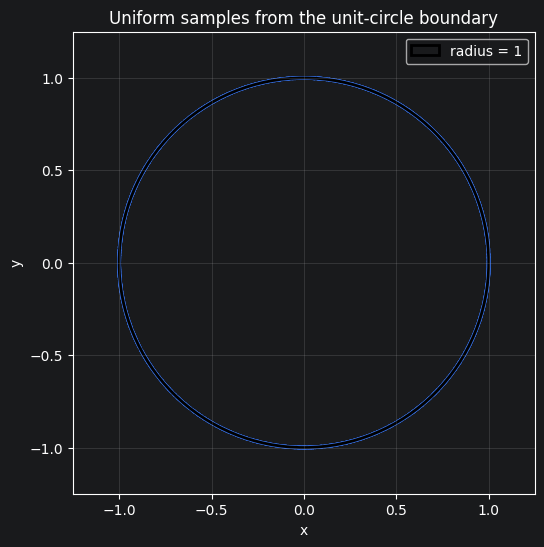

In [222]:
import numpy as np
import matplotlib.pyplot as plt

# Uniform sampling from the unit-circle boundary, S^1.
rng = np.random.default_rng(42)
n_points = 5000
radius = 1.0
plot_limit = 1.25

theta = rng.uniform(0.0, 2.0 * np.pi, n_points)
points = radius * np.column_stack((np.cos(theta), np.sin(theta)))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.6, edgecolors="none")

circle_boundary = plt.Circle(
    (0, 0), radius, fill=False, color="black", linewidth=2, label="radius = 1"
)
ax.add_patch(circle_boundary)

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Uniform samples from the unit-circle boundary")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

Left Gaussian radial range: 0.9999999999999999 1.0
Right Gaussian radial range: 0.9999999999999999 1.0


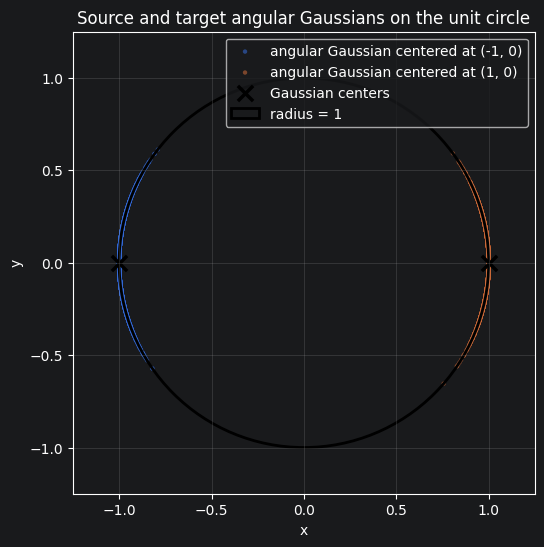

In [223]:
import numpy as np
import matplotlib.pyplot as plt

# Source and target clouds are angular Gaussians centered at the left and right
# points of the unit circle, then mapped onto S^1.
rng = np.random.default_rng(123)
radius = 1.0
plot_limit = 1.25
angular_variance = 0.04
angular_std = np.sqrt(angular_variance)
n_points_per_gaussian = 2500

mean_left = np.array([-radius, 0.0])
mean_right = np.array([radius, 0.0])
angle_left = np.pi
angle_right = 0.0


def angles_to_circle(theta, radius=1.0):
    return radius * np.column_stack((np.cos(theta), np.sin(theta)))


def sample_angular_gaussian_on_circle(mean_angle, angular_std, n_samples, rng, radius=1.0):
    theta = rng.normal(loc=mean_angle, scale=angular_std, size=n_samples)
    return angles_to_circle(theta, radius=radius), theta


left_gaussian_points, left_gaussian_angles = sample_angular_gaussian_on_circle(
    angle_left, angular_std, n_points_per_gaussian, rng, radius
)
right_gaussian_points, right_gaussian_angles = sample_angular_gaussian_on_circle(
    angle_right, angular_std, n_points_per_gaussian, rng, radius
)

gaussian_circle_points = np.vstack((left_gaussian_points, right_gaussian_points))
gaussian_circle_labels = np.concatenate(
    (
        np.zeros(n_points_per_gaussian, dtype=int),
        np.ones(n_points_per_gaussian, dtype=int),
    )
)

print("Left Gaussian radial range:", np.linalg.norm(left_gaussian_points, axis=1).min(), np.linalg.norm(left_gaussian_points, axis=1).max())
print("Right Gaussian radial range:", np.linalg.norm(right_gaussian_points, axis=1).min(), np.linalg.norm(right_gaussian_points, axis=1).max())

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    left_gaussian_points[:, 0],
    left_gaussian_points[:, 1],
    s=10,
    alpha=0.55,
    edgecolors="none",
    label="angular Gaussian centered at (-1, 0)",
)
ax.scatter(
    right_gaussian_points[:, 0],
    right_gaussian_points[:, 1],
    s=10,
    alpha=0.55,
    edgecolors="none",
    label="angular Gaussian centered at (1, 0)",
)
ax.scatter(
    [mean_left[0], mean_right[0]],
    [mean_left[1], mean_right[1]],
    marker="x",
    s=120,
    linewidths=2.5,
    color="black",
    label="Gaussian centers",
)

circle_boundary = plt.Circle(
    (0, 0), radius, fill=False, color="black", linewidth=2, label="radius = 1"
)
ax.add_patch(circle_boundary)

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Source and target angular Gaussians on the unit circle")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

## Approximate the unit-circle data manifold and pre-metric

We now follow the same pipeline as `riemannian_cell_flow.ipynb`: combine all generated points, build a weighted kNN graph, compute a normalized graph Laplacian, keep the first non-trivial eigenvectors, and use their biharmonic spectral embedding as the pre-metric space.

all_generated_points shape: (10000, 2)
construction_points shape: (5000, 2)
construction source: uniform circle samples only
source counts:
  uniform circle: 5000
  left Gaussian: 2500
  right Gaussian: 2500


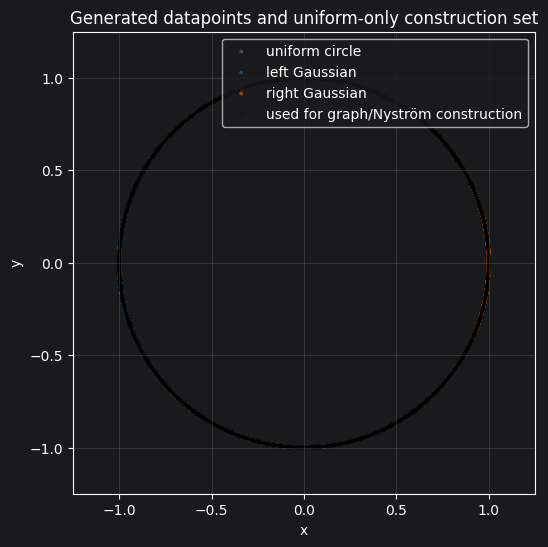

In [224]:
all_generated_points = np.vstack((points, gaussian_circle_points))
construction_points = points.astype(np.float32)

source_labels = np.concatenate(
    (
        np.full(points.shape[0], "uniform circle", dtype=object),
        np.where(gaussian_circle_labels == 0, "left Gaussian", "right Gaussian").astype(object),
    )
)

source_palette = {
    "uniform circle": "tab:gray",
    "left Gaussian": "tab:blue",
    "right Gaussian": "tab:orange",
}
source_colors = np.array([source_palette[label] for label in source_labels])

print("all_generated_points shape:", all_generated_points.shape)
print("construction_points shape:", construction_points.shape)
print("construction source: uniform circle samples only")
print("source counts:")
for label in source_palette:
    print(f"  {label}: {np.sum(source_labels == label)}")

fig, ax = plt.subplots(figsize=(7, 6))
for label, color in source_palette.items():
    mask = source_labels == label
    ax.scatter(
        all_generated_points[mask, 0],
        all_generated_points[mask, 1],
        s=8,
        alpha=0.45,
        edgecolors="none",
        color=color,
        label=label,
    )

ax.scatter(
    construction_points[:, 0],
    construction_points[:, 1],
    s=10,
    alpha=0.18,
    edgecolors="none",
    color="black",
    label="used for graph/Nyström construction",
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Generated datapoints and uniform-only construction set")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

### Build a weighted kNN graph

The graph is the discrete approximation of the unit-circle data manifold. Here `sigma=None` uses the median non-self kNN distance as the Gaussian bandwidth, which is scale-appropriate for the toy coordinates.

In [225]:
from scipy.sparse.csgraph import connected_components
from cellflow.preprocessing._premetric import (
    SpectralNystroem,
    build_knn_graph,
    compute_eigens,
    normalized_laplacian,
    spectral_embedding,
)
import jax.numpy as jnp

knn_k = 500
W, sigma = build_knn_graph(
    construction_points,
    k=knn_k,
    sigma=None,
    symmetrize='max',
    remove_self=True,
)

diag = W.diagonal()
print('construction_points shape:', construction_points.shape)
print('construction source: uniform circle samples only')
print('diagonal min:', diag.min())
print('diagonal max:', diag.max())
print('diagonal mean:', diag.mean())
print('nonzero diagonal count:', np.sum(diag != 0))

n_components, component_labels = connected_components(W, directed=False)
component_sizes = np.bincount(component_labels)
print('number of connected components:', n_components)
print('component sizes:', np.sort(component_sizes)[::-1][:20])

W_no_diag = W.copy()
W_no_diag.setdiag(0)
W_no_diag.eliminate_zeros()

print('non-self weight min:', W_no_diag.data.min())
print('non-self weight median:', np.median(W_no_diag.data))
print('non-self weight max:', W_no_diag.data.max())
print('non-self nnz:', W_no_diag.nnz)
print('sigma:', sigma)
print('weight quantiles:')
print(np.quantile(W_no_diag.data, [0, 0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 1.0]))

construction_points shape: (5000, 2)
construction source: uniform circle samples only
diagonal min: 0.0
diagonal max: 0.0
diagonal mean: 0.0
nonzero diagonal count: 0
number of connected components: 1
component sizes: [5000]
non-self weight min: 0.09819224095095945
non-self weight median: 0.5970517044559677
non-self weight max: 0.9999999999741103
non-self nnz: 2539286
sigma: 0.1571636652660861
weight quantiles:
[0.09819224 0.10992509 0.12380766 0.15657071 0.5970517  0.99479134
 0.99979502 1.        ]


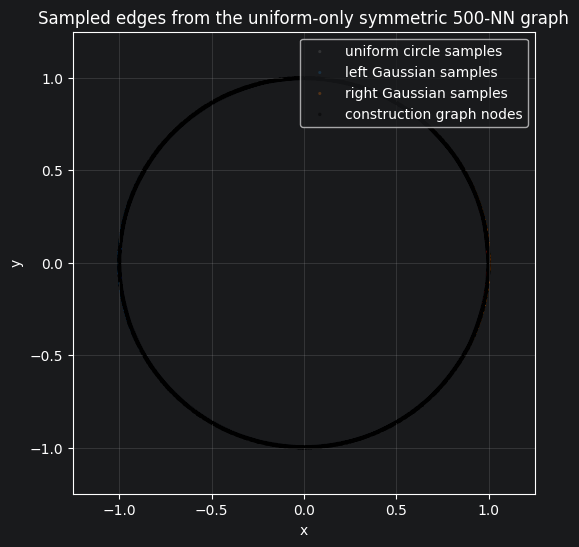

In [226]:
graph_rng = np.random.default_rng(7)
W_edges = W_no_diag.tocoo()
upper_edge_mask = W_edges.row < W_edges.col
edge_rows = W_edges.row[upper_edge_mask]
edge_cols = W_edges.col[upper_edge_mask]
edge_ids = graph_rng.choice(
    len(edge_rows),
    size=min(5_000, len(edge_rows)),
    replace=False,
)

fig, ax = plt.subplots(figsize=(7, 6))
for edge_id in edge_ids:
    i = edge_rows[edge_id]
    j = edge_cols[edge_id]
    ax.plot(
        construction_points[[i, j], 0],
        construction_points[[i, j], 1],
        color="black",
        alpha=0.015,
        linewidth=0.5,
    )

for label, color in source_palette.items():
    mask = source_labels == label
    ax.scatter(
        all_generated_points[mask, 0],
        all_generated_points[mask, 1],
        s=5,
        alpha=0.25,
        edgecolors="none",
        color=color,
        label=f"{label} samples",
    )

ax.scatter(
    construction_points[:, 0],
    construction_points[:, 1],
    s=6,
    alpha=0.45,
    edgecolors="none",
    color="black",
    label="construction graph nodes",
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Sampled edges from the uniform-only symmetric {knn_k}-NN graph")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

### Laplacian eigenvectors and spectral pre-metric coordinates

We remove the trivial constant eigenvector and use the next eigenvectors to construct biharmonic spectral coordinates. Before applying the biharmonic inverse-eigenvalue weighting, we rescale graph eigenvalues by `sigma^2` so the pre-metric is less dominated by the raw kNN graph scale.

construction_points shape: (5000, 2)
raw eigenvalues: [2.27255647e-13 9.50544877e-03 9.77382725e-03 3.74162544e-02
 3.90335460e-02 8.03244896e-02 8.87373971e-02 1.43934028e-01
 1.49561946e-01 2.17601330e-01 2.24386575e-01 2.97173427e-01
 3.15747745e-01 3.94469913e-01 3.98113801e-01 4.86786930e-01
 4.92116368e-01 5.75738832e-01 5.88318579e-01 6.65807389e-01
 6.71669169e-01 7.45886931e-01 7.52450054e-01 8.18608530e-01
 8.19760445e-01 8.78855889e-01 8.79599819e-01 9.26764473e-01
 9.27667119e-01 9.63011705e-01 9.64273208e-01 9.75946424e-01
 9.76790119e-01 9.79005646e-01 9.80011155e-01 9.80694486e-01
 9.81457650e-01 9.82907966e-01 9.83237746e-01 9.85237696e-01
 9.85346179e-01 9.86792467e-01 9.87423350e-01 9.88113309e-01
 9.88488558e-01 9.88718932e-01 9.88811084e-01 9.89173155e-01
 9.89333215e-01 9.89659427e-01 9.90174225e-01]
kept graph eigenvalues: [0.00950545 0.00977383 0.03741625 0.03903355 0.08032449 0.0887374
 0.14393403 0.14956195 0.21760133 0.22438658 0.29717343 0.31574774
 0.3944699

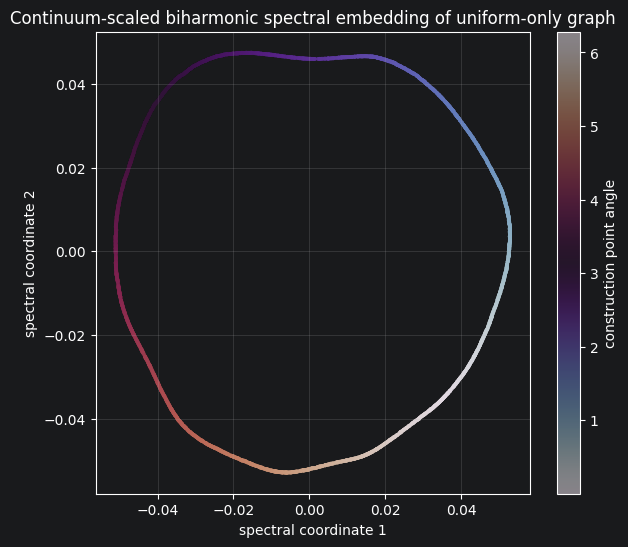

In [227]:
L = normalized_laplacian(W)

n_nontrivial_eigenvectors = 50
np.random.seed(0)
raw_evals, raw_evecs = compute_eigens(L, k=n_nontrivial_eigenvectors + 1)

order = np.argsort(raw_evals)
raw_evals = raw_evals[order]
raw_evecs = raw_evecs[:, order]

evals = raw_evals[1 : n_nontrivial_eigenvectors + 1]
evecs = raw_evecs[:, 1 : n_nontrivial_eigenvectors + 1]

if np.any(evals <= 0):
    print('Warning: non-positive non-trivial eigenvalues were clipped before spectral scaling.')
    evals = np.maximum(evals, 1e-12)

biharmonic_eps = 1e-8
graph_to_continuum_laplacian_scale = sigma**2
continuum_evals = evals / graph_to_continuum_laplacian_scale
biharmonic_spectral_scale = 1.0 / (continuum_evals + biharmonic_eps)
Psi = (evecs * biharmonic_spectral_scale[None, :]).astype(np.float32)
Psi_norm = np.sum(Psi * Psi, axis=1)
construction_angles = np.mod(
    np.arctan2(construction_points[:, 1], construction_points[:, 0]),
    2.0 * np.pi,
)

print('construction_points shape:', construction_points.shape)
print('raw eigenvalues:', raw_evals[: n_nontrivial_eigenvectors + 1])
print('kept graph eigenvalues:', evals)
print('sigma^2 graph-to-continuum scale:', graph_to_continuum_laplacian_scale)
print('continuum-scaled eigenvalue range:', (continuum_evals.min(), continuum_evals.max()))
print('biharmonic spectral scale range:', (biharmonic_spectral_scale.min(), biharmonic_spectral_scale.max()))
print('Psi shape:', Psi.shape)
print('Psi norm range:', (Psi_norm.min(), Psi_norm.max()))

fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(
    Psi[:, 0],
    Psi[:, 1],
    c=construction_angles,
    cmap='twilight',
    s=8,
    alpha=0.55,
    edgecolors='none',
)
ax.set_xlabel('spectral coordinate 1')
ax.set_ylabel('spectral coordinate 2')
ax.set_title('Continuum-scaled biharmonic spectral embedding of uniform-only graph')
ax.grid(alpha=0.25)
fig.colorbar(scatter, ax=ax, label='construction point angle')
plt.show()

### Pointwise spectral distances to one graph target

Sample representative graph vertices around the unit circle, choose the graph vertex closest to `(1, 0)` as a fixed target, and compare the continuum-scaled biharmonic distance against diffusion distance from that target.

target index: 2210
target construction point: [ 0.9999989  -0.00147443]
biharmonic scale correction: lambda_continuum = lambda_graph / sigma^2
sample index | angle(rad) | biharmonic distance | diffusion distance
 4889 |    6.2814 |         8.61534e-05 |         0.00187755
 3096 |    0.5250 |           0.0323268 |           0.100214
   83 |    1.0491 |           0.0572939 |           0.107018
 4150 |    1.5707 |            0.076093 |           0.102619
 1884 |    2.0958 |           0.0882519 |           0.101006
 1144 |    2.6180 |           0.0996256 |           0.105192
 1852 |    3.1429 |            0.104264 |           0.105862
 2448 |    3.6630 |           0.0993252 |           0.106075
 2934 |    4.1898 |           0.0903803 |           0.103488
  616 |    4.7123 |           0.0766861 |          0.0989716
  290 |    5.2368 |             0.05803 |           0.109256
 3202 |    5.7597 |           0.0326052 |          0.0970513


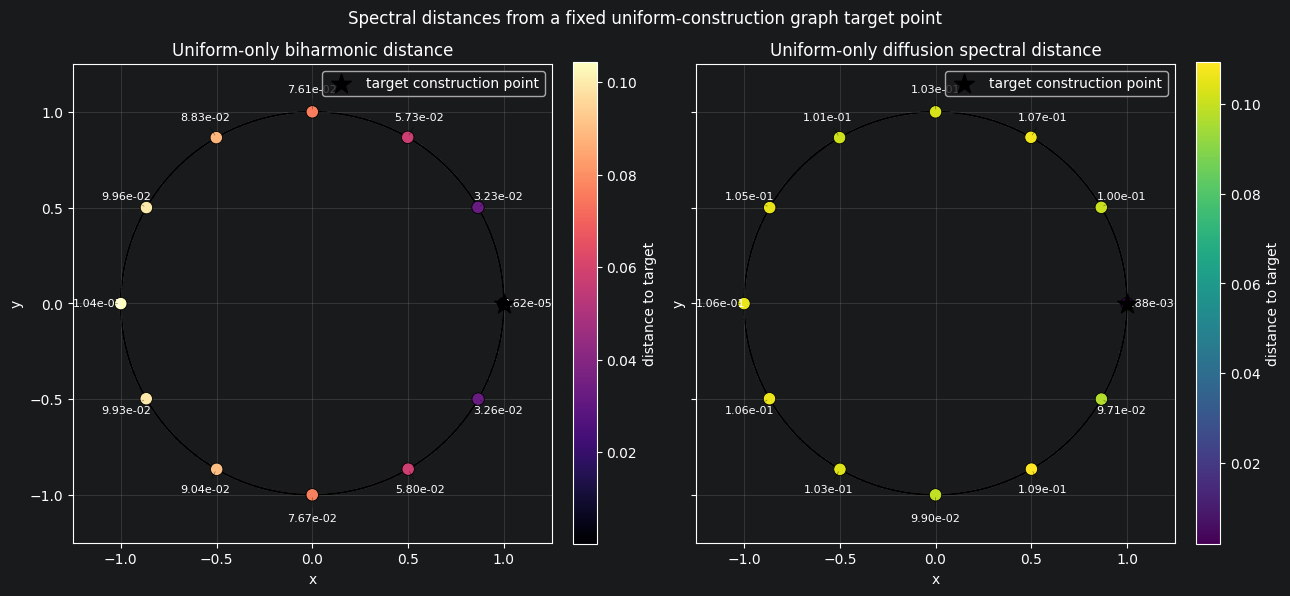

In [228]:
target_angle = 0.0
target_point = radius * np.array([np.cos(target_angle), np.sin(target_angle)])
target_index = int(np.argmin(np.linalg.norm(construction_points - target_point[None, :], axis=1)))

n_distance_samples = 12
candidate_angles = np.linspace(0.0, 2.0 * np.pi, n_distance_samples, endpoint=False)
point_angles = np.mod(np.arctan2(construction_points[:, 1], construction_points[:, 0]), 2.0 * np.pi)

sample_indices = []
used_indices = {target_index}
for angle in candidate_angles:
    circular_delta = np.abs(np.angle(np.exp(1j * (point_angles - angle))))
    for candidate_index in np.argsort(circular_delta):
        candidate_index = int(candidate_index)
        if candidate_index not in used_indices:
            sample_indices.append(candidate_index)
            used_indices.add(candidate_index)
            break
sample_indices = np.array(sample_indices, dtype=int)

Psi_biharmonic = Psi
Psi_diffusion = spectral_embedding(evals, evecs, weight_type='diffusion').astype(np.float32)

biharmonic_distances = np.linalg.norm(
    Psi_biharmonic[sample_indices] - Psi_biharmonic[target_index][None, :], axis=1
)
diffusion_distances = np.linalg.norm(
    Psi_diffusion[sample_indices] - Psi_diffusion[target_index][None, :], axis=1
)

print('target index:', target_index)
print('target construction point:', construction_points[target_index])
print('biharmonic scale correction: lambda_continuum = lambda_graph / sigma^2')
print('sample index | angle(rad) | biharmonic distance | diffusion distance')
for index, angle, biharmonic_distance, diffusion_distance in zip(
    sample_indices,
    point_angles[sample_indices],
    biharmonic_distances,
    diffusion_distances,
):
    print(f'{index:5d} | {angle:9.4f} | {biharmonic_distance:19.6g} | {diffusion_distance:18.6g}')

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
distance_panels = [
    ('Uniform-only biharmonic distance', biharmonic_distances, 'magma'),
    ('Uniform-only diffusion spectral distance', diffusion_distances, 'viridis'),
]
label_radius = 1.12 * radius

for ax, (title, distances, cmap) in zip(axes, distance_panels):
    ax.scatter(
        construction_points[:, 0],
        construction_points[:, 1],
        s=3,
        alpha=0.10,
        color='tab:gray',
        edgecolors='none',
    )
    scatter = ax.scatter(
        construction_points[sample_indices, 0],
        construction_points[sample_indices, 1],
        c=distances,
        cmap=cmap,
        s=80,
        edgecolors='black',
        linewidths=0.6,
        zorder=3,
    )
    ax.scatter(
        construction_points[target_index, 0],
        construction_points[target_index, 1],
        marker='*',
        s=220,
        color='black',
        label='target construction point',
        zorder=4,
    )

    for index, distance in zip(sample_indices, distances):
        point = construction_points[index]
        direction = point / max(np.linalg.norm(point), 1e-12)
        label_xy = direction * label_radius
        ax.annotate(
            f'{distance:.2e}',
            xy=point,
            xytext=label_xy,
            textcoords='data',
            ha='center',
            va='center',
            fontsize=8,
            arrowprops={'arrowstyle': '-', 'linewidth': 0.5, 'alpha': 0.45},
        )

    ax.add_patch(plt.Circle((0, 0), radius, fill=False, color='black', linewidth=1.5))
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-plot_limit, plot_limit)
    ax.set_ylim(-plot_limit, plot_limit)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc='upper right')
    fig.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04, label='distance to target')

fig.suptitle('Spectral distances from a fixed uniform-construction graph target point')
plt.tight_layout()
plt.show()

### Precompute the dense squared pre-metric

For 10,000 generated points, a dense float32 matrix takes about 400 MB. The helper below computes squared distances in the continuum-scaled biharmonic `Psi` coordinates in row blocks so the temporary matrix products stay bounded.

D shape: (5000, 5000)
D indexes construction_points only: True
D dtype: float32
D memory GB: 0.09313225746154785
max diagonal entry: 0.0
sample symmetry error: 0.0
five nearest construction points to point 0 by pre-metric: [2137 3348  638  366 1105]
their squared pre-metric distances: [4.65661287e-10 1.21071935e-08 1.62981451e-08 4.74974513e-08
 4.84287739e-08]


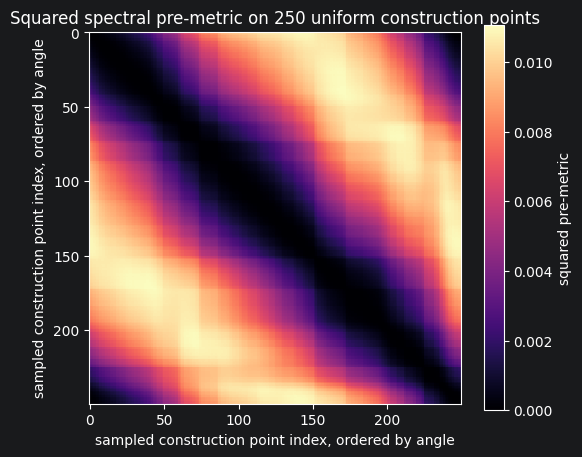

In [229]:
def squared_spectral_distance_matrix(psi, block_size=1_000, dtype=np.float32):
    psi = np.asarray(psi, dtype=dtype)
    sq_norm = np.sum(psi * psi, axis=1, dtype=dtype)
    distances = np.empty((psi.shape[0], psi.shape[0]), dtype=dtype)

    for start in range(0, psi.shape[0], block_size):
        stop = min(start + block_size, psi.shape[0])
        distances[start:stop] = (
            sq_norm[start:stop, None]
            + sq_norm[None, :]
            - 2.0 * (psi[start:stop] @ psi.T)
        )

    np.maximum(distances, 0, out=distances)
    np.fill_diagonal(distances, 0.0)
    return distances

dense_premetric_block_size = 1_000
D = squared_spectral_distance_matrix(Psi, block_size=dense_premetric_block_size)

check_rng = np.random.default_rng(13)
check_ids = check_rng.choice(D.shape[0], size=min(512, D.shape[0]), replace=False)
D_check = D[np.ix_(check_ids, check_ids)]

query_index = 0
nearest_by_premetric = np.argsort(D[query_index])[1:6]

print("D shape:", D.shape)
print("D indexes construction_points only:", D.shape[0] == construction_points.shape[0])
print("D dtype:", D.dtype)
print("D memory GB:", D.nbytes / 1024**3)
print("max diagonal entry:", np.max(np.diag(D)))
print("sample symmetry error:", np.max(np.abs(D_check - D_check.T)))
print("five nearest construction points to point 0 by pre-metric:", nearest_by_premetric)
print("their squared pre-metric distances:", D[query_index, nearest_by_premetric])

heatmap_rng = np.random.default_rng(19)
heatmap_ids = heatmap_rng.choice(D.shape[0], size=250, replace=False)
heatmap_angles = np.arctan2(construction_points[heatmap_ids, 1], construction_points[heatmap_ids, 0])
heatmap_ids = heatmap_ids[np.argsort(heatmap_angles)]

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(D[np.ix_(heatmap_ids, heatmap_ids)], cmap="magma", interpolation="nearest")
ax.set_title("Squared spectral pre-metric on 250 uniform construction points")
ax.set_xlabel("sampled construction point index, ordered by angle")
ax.set_ylabel("sampled construction point index, ordered by angle")
fig.colorbar(image, ax=ax, label="squared pre-metric")
plt.show()

### Stream new points into the pre-metric space

The precomputed graph eigenvectors also give a Nystroem-style interpolator for points that were not in the graph fit.

new point: [1. 0.]
Nystroem construction_points shape: (5000, 2)
graph/Nystroem sigma: 0.1571636652660861
Nystroem dropped spectral components: 0
nearest uniform construction points by streamed pre-metric: [1157 1836 3502 2210 4889 3150 1130 3303 2920 4641]
squared pre-metric distances: [1.9188570e-07 2.0973559e-07 2.2360982e-07 2.4671249e-07 2.9753753e-07
 3.3890166e-07 3.6212558e-07 3.6426974e-07 3.6719427e-07 4.5050555e-07]


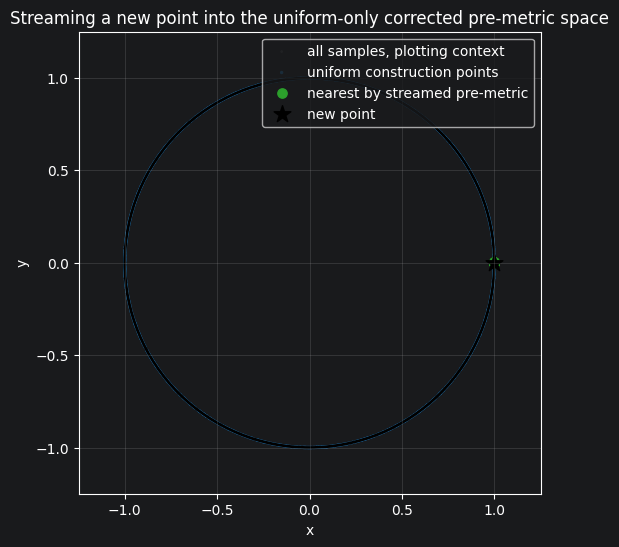

In [230]:
key_array = jnp.asarray(construction_points)
nystroem = SpectralNystroem(
    construction_points,
    evecs,
    evals,
    sigma=sigma,
    psi=Psi,
    x_to_id=key_array,
    k=knn_k,
    spectral_scale=biharmonic_spectral_scale,
    spectral_weight_type='biharmonic',
    drop_trivial_eigenvectors=False,
)

new_point = np.array([radius, 0], dtype=np.float32)
new_emb = np.asarray(nystroem.embed_point(jnp.asarray(new_point))).astype(np.float32)
new_point_distances = np.sum((Psi - new_emb[None, :]) ** 2, axis=1)
nearest_to_new_point = np.argsort(new_point_distances)[:10]

print('new point:', new_point)
print('Nystroem construction_points shape:', construction_points.shape)
print('graph/Nystroem sigma:', sigma)
print('Nystroem dropped spectral components:', nystroem.n_dropped_spectral_components)
print('nearest uniform construction points by streamed pre-metric:', nearest_to_new_point)
print('squared pre-metric distances:', new_point_distances[nearest_to_new_point])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    all_generated_points[:, 0],
    all_generated_points[:, 1],
    s=4,
    alpha=0.08,
    edgecolors='none',
    color='tab:gray',
    label='all samples, plotting context',
)
ax.scatter(
    construction_points[:, 0],
    construction_points[:, 1],
    s=6,
    alpha=0.20,
    edgecolors='none',
    color='tab:blue',
    label='uniform construction points',
)
ax.scatter(
    construction_points[nearest_to_new_point, 0],
    construction_points[nearest_to_new_point, 1],
    s=45,
    color='tab:green',
    label='nearest by streamed pre-metric',
)
ax.scatter(
    new_point[0],
    new_point[1],
    s=160,
    marker='*',
    color='black',
    label='new point',
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color='black', linewidth=2))
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Streaming a new point into the uniform-only corrected pre-metric space')
ax.legend(loc='upper right')
ax.grid(alpha=0.25)
plt.show()

### Inspect the RFM interpolation field `u_t`

The `RFMInterpolation` class defines the target-conditioned field used inside `OTRFlowMatching`. The plot below samples evenly around the unit circle and separates the ambient `u_t` direction from the tangent direction that remains relevant after projection back to the circle.

target x1: [ 9.9999988e-01 -4.5917244e-04]
target angle: 6.2827263
sampled circle directions: 72
u_t speed range: (np.float32(0.00091913), np.float32(21.631569))
tangent speed range: (np.float32(0.00091909256), np.float32(11.692569))
median absolute radial fraction: 0.30796158


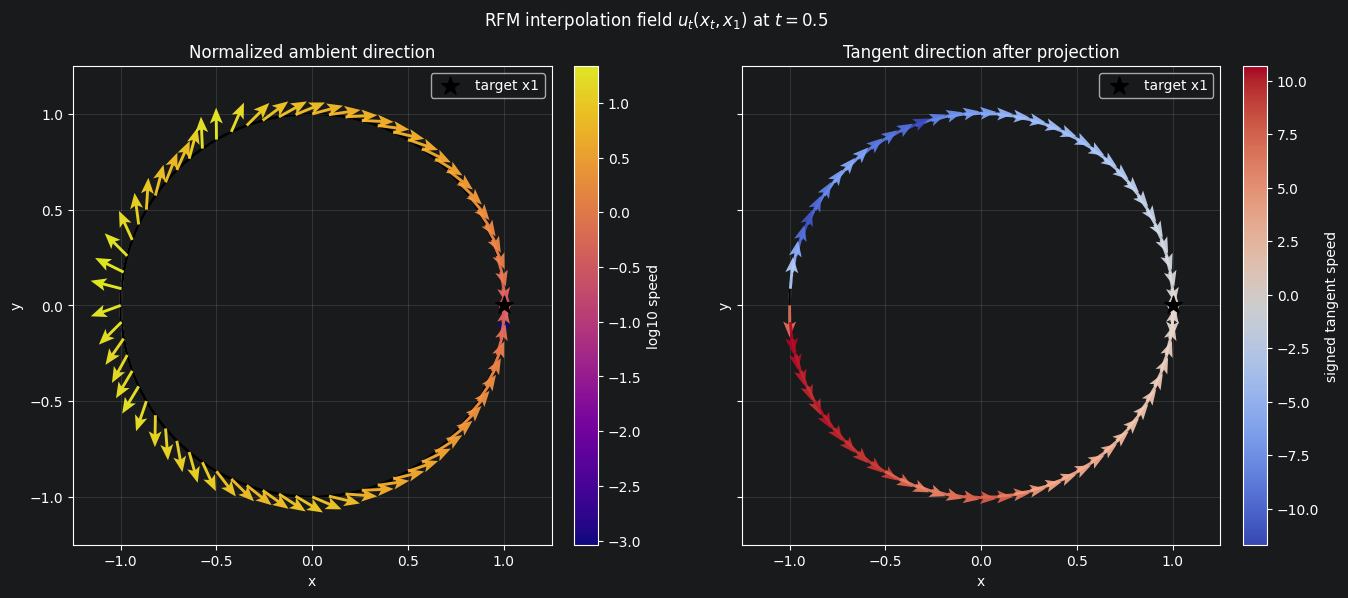

In [231]:
from cellflow.ode_solver import RFMInterpolation, project_to_unit_sphere

rfm_interpolator = RFMInterpolation(nystroem, projection_fn=project_to_unit_sphere)

rfm_target_local_idx = int(np.argmin(np.linalg.norm(right_gaussian_points - mean_right, axis=1)))
x1 = right_gaussian_points[rfm_target_local_idx].astype(np.float32)

n_ut_vectors = 72
ut_angles = np.linspace(0.0, 2.0 * np.pi, n_ut_vectors, endpoint=False, dtype=np.float32)
xt_samples = radius * np.column_stack((np.cos(ut_angles), np.sin(ut_angles))).astype(np.float32)
x1_batch = np.repeat(x1[None, :], xt_samples.shape[0], axis=0)

ut_time = 0.5
u_samples = np.asarray(
    rfm_interpolator.u_t(
        jnp.asarray(xt_samples),
        jnp.asarray(x1_batch),
        ut_time,
    )
)
u_speed = np.linalg.norm(u_samples, axis=1)

radial_directions = xt_samples / np.maximum(np.linalg.norm(xt_samples, axis=1, keepdims=True), 1e-8)
tangent_directions_ccw = np.column_stack((-radial_directions[:, 1], radial_directions[:, 0]))
u_radial_component = np.sum(u_samples * radial_directions, axis=1)
u_tangent_component = np.sum(u_samples * tangent_directions_ccw, axis=1)
u_tangent = u_tangent_component[:, None] * tangent_directions_ccw
u_tangent_speed = np.abs(u_tangent_component)

u_directions = u_samples / np.maximum(u_speed[:, None], 1e-8)
u_tangent_directions = u_tangent / np.maximum(u_tangent_speed[:, None], 1e-8)
log_speed = np.log10(np.maximum(u_speed, 1e-8))

target_angle = np.mod(np.arctan2(x1[1], x1[0]), 2.0 * np.pi)

print("target x1:", x1)
print("target angle:", target_angle)
print("sampled circle directions:", n_ut_vectors)
print("u_t speed range:", (u_speed.min(), u_speed.max()))
print("tangent speed range:", (u_tangent_speed.min(), u_tangent_speed.max()))
print("median absolute radial fraction:", np.median(np.abs(u_radial_component) / np.maximum(u_speed, 1e-8)))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
panels = [
    (
        axes[0],
        u_directions,
        log_speed,
        "Normalized ambient direction",
        "plasma",
        "log10 speed",
    ),
    (
        axes[1],
        u_tangent_directions,
        u_tangent_component,
        "Tangent direction after projection",
        "coolwarm",
        "signed tangent speed",
    ),
]

for ax, directions, color_values, title, cmap, colorbar_label in panels:
    ax.scatter(
        all_generated_points[:, 0],
        all_generated_points[:, 1],
        s=4,
        alpha=0.07,
        edgecolors="none",
        color="tab:gray",
    )
    quiver = ax.quiver(
        xt_samples[:, 0],
        xt_samples[:, 1],
        directions[:, 0],
        directions[:, 1],
        color_values,
        cmap=cmap,
        angles="xy",
        scale_units="xy",
        scale=6,
        width=0.006,
        headwidth=4.5,
        headlength=5.5,
        headaxislength=4.5,
        alpha=0.92,
        zorder=3,
    )
    ax.scatter(
        x1[0],
        x1[1],
        s=180,
        marker="*",
        color="black",
        label="target x1",
        zorder=4,
    )
    ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-plot_limit, plot_limit)
    ax.set_ylim(-plot_limit, plot_limit)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)
    fig.colorbar(quiver, ax=ax, fraction=0.046, pad=0.04, label=colorbar_label)

fig.suptitle(r"RFM interpolation field $u_t(x_t, x_1)$ at $t = 0.5$")
plt.tight_layout()
plt.show()

start x0: [ 0 -1]
target x1: [ 9.9999988e-01 -4.5917244e-04]
last interpolated point: [ 0.99993306 -0.01156881]
distance from last interpolated point to x1: 0.011109842


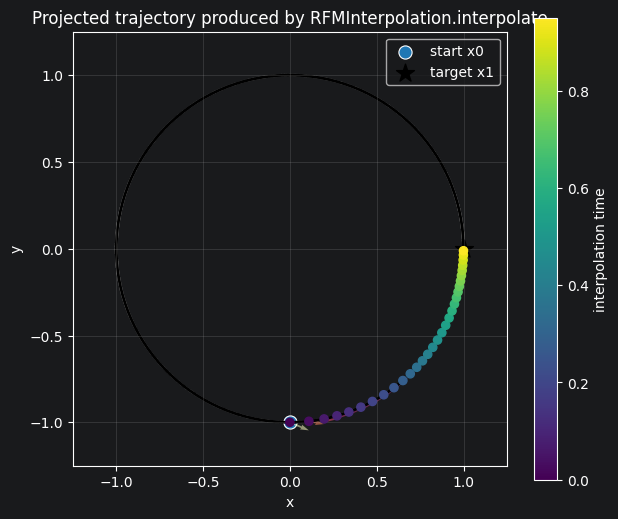

In [232]:
rfm_start_local_idx = int(np.argmin(np.linalg.norm(left_gaussian_points - mean_left, axis=1)))
x0 = np.array([0,-1])

trajectory_times = np.linspace(0.0, 0.95, 31, dtype=np.float32)
trajectory_steps_per_eval = 250
rfm_trajectory = np.vstack(
    [
        np.asarray(
            rfm_interpolator.interpolate(
                jnp.asarray(x0[None, :]),
                jnp.asarray(x1[None, :]),
                float(t),
                trajectory_steps_per_eval,
            )
        )[0]
        for t in trajectory_times
    ]
)

trajectory_vectors = np.asarray(
    rfm_interpolator.u_t(
        jnp.asarray(rfm_trajectory),
        jnp.asarray(np.repeat(x1[None, :], rfm_trajectory.shape[0], axis=0)),
        0.5,
    )
)
trajectory_speed = np.linalg.norm(trajectory_vectors, axis=1)

print("start x0:", x0)
print("target x1:", x1)
print("last interpolated point:", rfm_trajectory[-1])
print("distance from last interpolated point to x1:", np.linalg.norm(rfm_trajectory[-1] - x1))

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    all_generated_points[:, 0],
    all_generated_points[:, 1],
    s=5,
    alpha=0.08,
    edgecolors="none",
    color="tab:gray",
)
path = ax.scatter(
    rfm_trajectory[:, 0],
    rfm_trajectory[:, 1],
    c=trajectory_times,
    cmap="viridis",
    s=35,
    zorder=3,
)
ax.plot(rfm_trajectory[:, 0], rfm_trajectory[:, 1], color="black", linewidth=1.5, alpha=0.75)
ax.scatter(x0[0], x0[1], s=90, color="tab:blue", edgecolors="white", linewidths=0.8, label="start x0")
ax.scatter(x1[0], x1[1], s=180, marker="*", color="black", label="target x1")
ax.quiver(
    rfm_trajectory[:, 0],
    rfm_trajectory[:, 1],
    trajectory_vectors[:, 0],
    trajectory_vectors[:, 1],
    trajectory_speed,
    cmap="magma",
    angles="xy",
    scale_units="xy",
    scale=70,
    width=0.004,
    alpha=0.55,
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Projected trajectory produced by RFMInterpolation.interpolate")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
fig.colorbar(path, ax=ax, label="interpolation time")
plt.show()

target x1: [ 9.9999988e-01 -4.5917244e-04]
target angle: 6.282726287841797
start angle offsets: [-0.4 -0.2  0.   0.2  0.4]
Euler substeps per interval: 25
total Euler intervals: 975
max radius error, ambient u_t: 1.1920929e-07
max radius error, tangent-projected u_t: 1.1920929e-07

Final trajectory diagnostics:
offset(rad) | final arc ambient | final arc tangent | final euclidean ambient | final euclidean tangent | path length ambient | path length tangent | max method sep
-0.400      |  0.0198            |  0.0197          |  0.0198                 |  0.0197               |  2.7223             |  2.7223           |  0.0052
-0.200      |  0.0217            |  0.0215          |  0.0217                 |  0.0215               |  2.9204             |  2.9205           |  0.0066
 0.000      |  0.0281            |  0.0280          |  0.0281                 |  0.0280               |  3.1130             |  3.1131           |  0.0052
 0.200      |  0.0255            |  0.0254          |  0.025

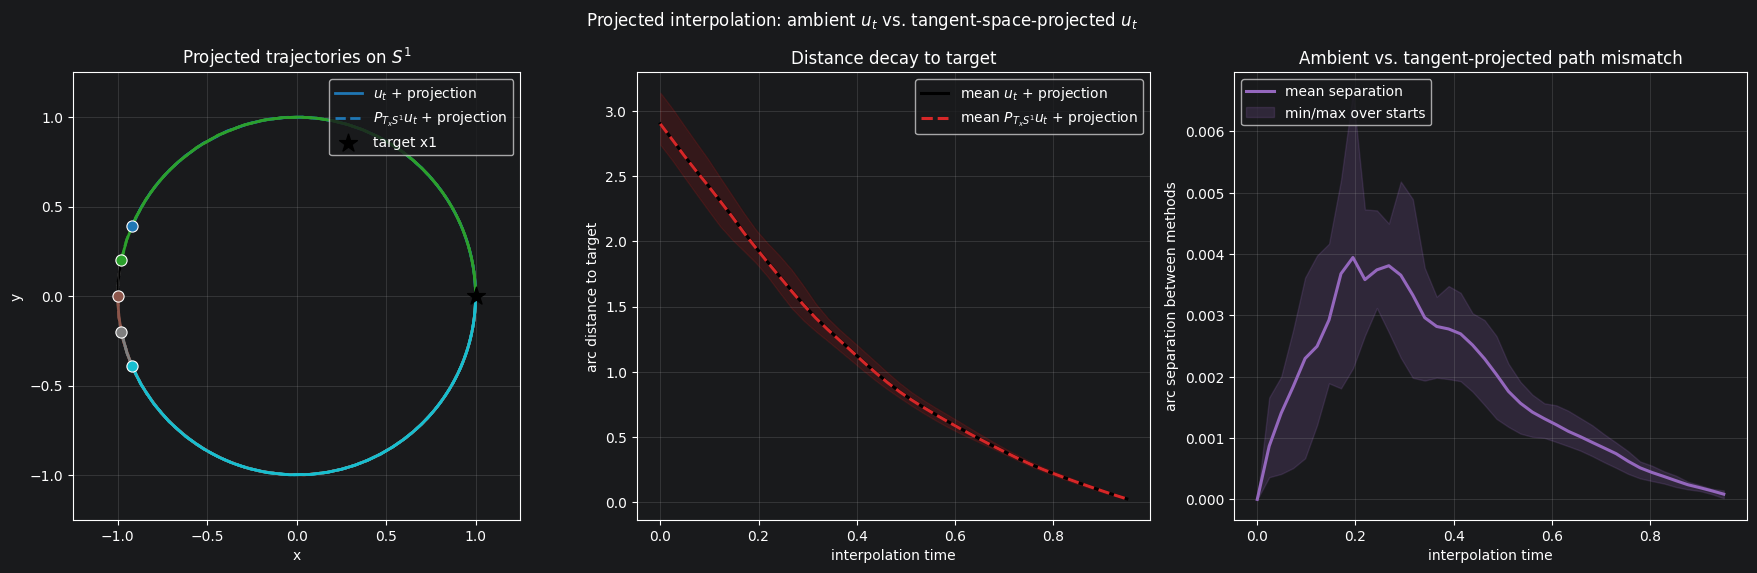

In [233]:
# Compare projected trajectories driven by ambient u_t vs. tangent-space-projected u_t.
# Both methods project back to S^1 after each Euler step; the only difference is
# whether the velocity itself is first projected to the tangent space at x_t.

def tangent_project_velocity_unit_circle(x, v, eps=1e-8):
    radial = x / jnp.maximum(jnp.linalg.norm(x, axis=1, keepdims=True), eps)
    radial_component = jnp.sum(v * radial, axis=1, keepdims=True) * radial
    return v - radial_component


def integrate_ambient_and_tangent_projected_paths(
    starts,
    target,
    eval_times,
    steps_per_interval=25,
):
    starts = np.asarray(starts, dtype=np.float32)
    target = np.asarray(target, dtype=np.float32)
    n_starts = starts.shape[0]

    xt_ambient = jnp.asarray(starts)
    xt_tangent = jnp.asarray(starts)
    target_batch = jnp.asarray(np.repeat(target[None, :], n_starts, axis=0))
    target_both = jnp.concatenate([target_batch, target_batch], axis=0)

    ambient_path = [np.asarray(xt_ambient)]
    tangent_path = [np.asarray(xt_tangent)]
    current_t = float(eval_times[0])

    for next_t in map(float, eval_times[1:]):
        dt = (next_t - current_t) / steps_per_interval
        for _ in range(steps_per_interval):
            xt_both = jnp.concatenate([xt_ambient, xt_tangent], axis=0)
            v_both = rfm_interpolator.u_t(xt_both, target_both, current_t)
            v_ambient = v_both[:n_starts]
            v_tangent = tangent_project_velocity_unit_circle(xt_tangent, v_both[n_starts:])

            xt_ambient = project_to_unit_sphere(xt_ambient + dt * v_ambient)
            xt_tangent = project_to_unit_sphere(xt_tangent + dt * v_tangent)
            current_t += dt

        ambient_path.append(np.asarray(xt_ambient))
        tangent_path.append(np.asarray(xt_tangent))

    return np.stack(ambient_path), np.stack(tangent_path)


def circle_angles(path):
    return np.mod(np.arctan2(path[..., 1], path[..., 0]), 2.0 * np.pi)


def signed_angle_delta(a, b):
    return (a - b + np.pi) % (2.0 * np.pi) - np.pi


comparison_angle_offsets = angular_std * np.array([-2.0, -1.0, 0.0, 1.0, 2.0], dtype=np.float32)
comparison_start_angles = angle_left + comparison_angle_offsets
comparison_starts = angles_to_circle(comparison_start_angles, radius=radius).astype(np.float32)

rfm_target_local_idx = int(np.argmin(np.linalg.norm(right_gaussian_points - mean_right, axis=1)))
x1 = right_gaussian_points[rfm_target_local_idx].astype(np.float32)
target_angle = float(np.mod(np.arctan2(x1[1], x1[0]), 2.0 * np.pi))

comparison_times = np.linspace(0.0, 0.95, 40, dtype=np.float32)
steps_per_interval = 25
ambient_paths, tangent_paths = integrate_ambient_and_tangent_projected_paths(
    comparison_starts,
    x1,
    comparison_times,
    steps_per_interval=steps_per_interval,
)

ambient_angles = circle_angles(ambient_paths)
tangent_angles = circle_angles(tangent_paths)
ambient_arc_to_target = radius * np.abs(signed_angle_delta(target_angle, ambient_angles))
tangent_arc_to_target = radius * np.abs(signed_angle_delta(target_angle, tangent_angles))
method_arc_separation = radius * np.abs(signed_angle_delta(ambient_angles, tangent_angles))

ambient_path_length = radius * np.sum(
    np.abs(signed_angle_delta(ambient_angles[1:], ambient_angles[:-1])), axis=0
)
tangent_path_length = radius * np.sum(
    np.abs(signed_angle_delta(tangent_angles[1:], tangent_angles[:-1])), axis=0
)

ambient_final_euclidean = np.linalg.norm(ambient_paths[-1] - x1[None, :], axis=1)
tangent_final_euclidean = np.linalg.norm(tangent_paths[-1] - x1[None, :], axis=1)
ambient_max_radius_error = np.max(np.abs(np.linalg.norm(ambient_paths, axis=-1) - radius))
tangent_max_radius_error = np.max(np.abs(np.linalg.norm(tangent_paths, axis=-1) - radius))

print("target x1:", x1)
print("target angle:", target_angle)
print("start angle offsets:", comparison_angle_offsets)
print("Euler substeps per interval:", steps_per_interval)
print("total Euler intervals:", (len(comparison_times) - 1) * steps_per_interval)
print("max radius error, ambient u_t:", ambient_max_radius_error)
print("max radius error, tangent-projected u_t:", tangent_max_radius_error)
print()
print("Final trajectory diagnostics:")
print("offset(rad) | final arc ambient | final arc tangent | final euclidean ambient | final euclidean tangent | path length ambient | path length tangent | max method sep")
for i, offset in enumerate(comparison_angle_offsets):
    print(
        f"{offset: .3f}      | "
        f"{ambient_arc_to_target[-1, i]: .4f}            | "
        f"{tangent_arc_to_target[-1, i]: .4f}          | "
        f"{ambient_final_euclidean[i]: .4f}                 | "
        f"{tangent_final_euclidean[i]: .4f}               | "
        f"{ambient_path_length[i]: .4f}             | "
        f"{tangent_path_length[i]: .4f}           | "
        f"{method_arc_separation[:, i].max(): .4f}"
    )

colors = plt.cm.tab10(np.linspace(0.0, 1.0, comparison_starts.shape[0]))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
ax_geo, ax_arc, ax_sep = axes

ax_geo.scatter(
    all_generated_points[:, 0],
    all_generated_points[:, 1],
    s=4,
    alpha=0.06,
    edgecolors="none",
    color="tab:gray",
)
for i, color in enumerate(colors):
    ax_geo.plot(
        ambient_paths[:, i, 0],
        ambient_paths[:, i, 1],
        color=color,
        linewidth=2.0,
        label=r"$u_t$ + projection" if i == 0 else None,
    )
    ax_geo.plot(
        tangent_paths[:, i, 0],
        tangent_paths[:, i, 1],
        color=color,
        linewidth=2.0,
        linestyle="--",
        label=r"$P_{T_xS^1}u_t$ + projection" if i == 0 else None,
    )
    ax_geo.scatter(
        comparison_starts[i, 0],
        comparison_starts[i, 1],
        s=65,
        color=color,
        edgecolors="white",
        linewidths=0.8,
        zorder=4,
    )
ax_geo.scatter(x1[0], x1[1], s=180, marker="*", color="black", label="target x1", zorder=5)
ax_geo.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax_geo.set_aspect("equal", adjustable="box")
ax_geo.set_xlim(-plot_limit, plot_limit)
ax_geo.set_ylim(-plot_limit, plot_limit)
ax_geo.set_xlabel("x")
ax_geo.set_ylabel("y")
ax_geo.set_title("Projected trajectories on $S^1$")
ax_geo.legend(loc="upper right")
ax_geo.grid(alpha=0.25)

ambient_mean = ambient_arc_to_target.mean(axis=1)
tangent_mean = tangent_arc_to_target.mean(axis=1)
ax_arc.plot(comparison_times, ambient_mean, color="black", linewidth=2.2, label=r"mean $u_t$ + projection")
ax_arc.plot(comparison_times, tangent_mean, color="tab:red", linestyle="--", linewidth=2.2, label=r"mean $P_{T_xS^1}u_t$ + projection")
ax_arc.fill_between(
    comparison_times,
    ambient_arc_to_target.min(axis=1),
    ambient_arc_to_target.max(axis=1),
    color="black",
    alpha=0.12,
)
ax_arc.fill_between(
    comparison_times,
    tangent_arc_to_target.min(axis=1),
    tangent_arc_to_target.max(axis=1),
    color="tab:red",
    alpha=0.16,
)
ax_arc.set_xlabel("interpolation time")
ax_arc.set_ylabel("arc distance to target")
ax_arc.set_title("Distance decay to target")
ax_arc.legend(loc="upper right")
ax_arc.grid(alpha=0.25)

ax_sep.plot(
    comparison_times,
    method_arc_separation.mean(axis=1),
    color="tab:purple",
    linewidth=2.2,
    label="mean separation",
)
ax_sep.fill_between(
    comparison_times,
    method_arc_separation.min(axis=1),
    method_arc_separation.max(axis=1),
    color="tab:purple",
    alpha=0.18,
    label="min/max over starts",
)
ax_sep.set_xlabel("interpolation time")
ax_sep.set_ylabel("arc separation between methods")
ax_sep.set_title("Ambient vs. tangent-projected path mismatch")
ax_sep.legend(loc="upper left")
ax_sep.grid(alpha=0.25)

fig.suptitle(r"Projected interpolation: ambient $u_t$ vs. tangent-space-projected $u_t$")
plt.tight_layout()
plt.show()

Paper-style field used here: pi(x) -> tangent projection -> spectral g^{-1/2}
target x1: [ 9.9999988e-01 -4.5917244e-04]
target angle: 6.282726287841797
start angle offsets: [-0.4 -0.2  0.   0.2  0.4]
Euler substeps per interval: 15
total Euler intervals: 525
metric floor quantile: 0.05
global median normalization of g^{-1/2}: True
spectral tangent metric quantiles: [0.00585286 0.00621785 0.00769763 0.0094266  0.0111218 ]
raw g^{-1/2} quantiles: [ 9.4822731  10.29965496 11.39781427 12.66894531 12.68177128]
normalized g^{-1/2} quantiles: [0.83193791 0.90365182 1.00000003 1.11152416 1.11264944]

Final diagnostics by method:
method | mean final arc | min final arc | max final arc | mean path length | max radius error
ambient $u_t$ + $\pi$ step |  0.0236 |  0.0197 |  0.0282 |  2.8779 |  1.192e-07
$P_T u_t$ + $\pi$ step |  0.0234 |  0.0195 |  0.0279 |  2.8781 |  1.192e-07
$g^{-1/2}P_Tu_t$ + $\pi$ step |  0.0211 |  0.0177 |  0.0251 |  2.8804 |  1.192e-07


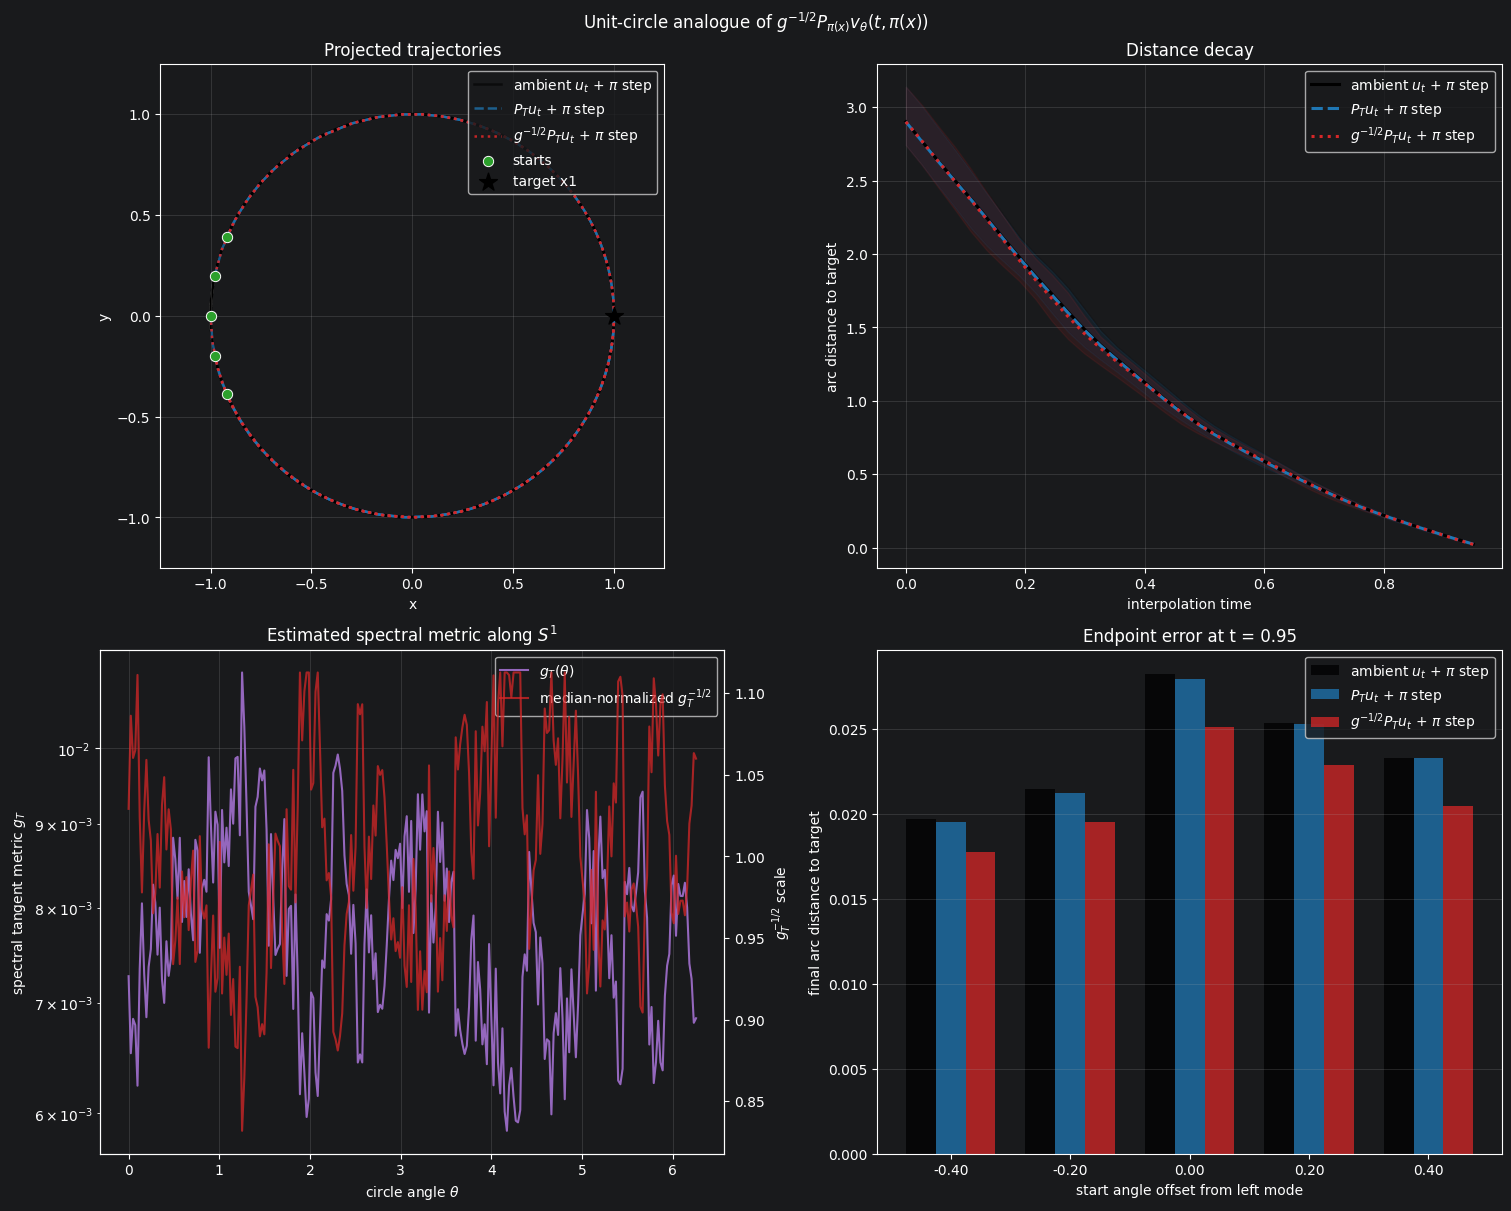

In [234]:
# Paper-style unit-circle vector field parameterization:
#     v(t, x) = g(pi(x))^{-1/2} P_{T_{pi(x)} S^1} u_t(t, pi(x), x1)
# Here u_t plays the role of the ambient vector field v_theta from the paper.
# The final projection after each Euler step is kept only as a numerical constraint.

import jax


def project_np_to_unit_circle(x, eps=1e-8):
    x = np.asarray(x, dtype=np.float32)
    norm = np.linalg.norm(x, axis=1, keepdims=True)
    return x / np.maximum(norm, eps)


def tangent_project_velocity_np(y, v, eps=1e-8):
    y = project_np_to_unit_circle(y, eps=eps)
    v = np.asarray(v, dtype=np.float32)
    radial_component = np.sum(v * y, axis=1, keepdims=True) * y
    return v - radial_component


def periodic_linear_interp(values, theta):
    values = np.asarray(values, dtype=np.float32)
    theta = np.mod(np.asarray(theta, dtype=np.float32), 2.0 * np.pi)
    n_values = values.shape[0]
    grid_position = theta / (2.0 * np.pi) * n_values
    left_idx = np.floor(grid_position).astype(int) % n_values
    right_idx = (left_idx + 1) % n_values
    frac = grid_position - np.floor(grid_position)
    return (1.0 - frac) * values[left_idx] + frac * values[right_idx]


def embed_nystroem_points(points_to_embed, chunk_size=64):
    points_to_embed = np.asarray(points_to_embed, dtype=np.float32)
    embeddings = []
    for start in range(0, points_to_embed.shape[0], chunk_size):
        stop = min(start + chunk_size, points_to_embed.shape[0])
        emb_chunk = jax.vmap(nystroem.embed_point)(jnp.asarray(points_to_embed[start:stop]))
        embeddings.append(np.asarray(emb_chunk))
    return np.vstack(embeddings).astype(np.float32)


def estimate_spectral_tangent_metric_on_circle(
    n_metric_grid=256,
    floor_quantile=0.05,
    normalize_global_scale=True,
):
    metric_theta = np.linspace(0.0, 2.0 * np.pi, n_metric_grid, endpoint=False, dtype=np.float32)
    metric_points = angles_to_circle(metric_theta, radius=radius).astype(np.float32)
    metric_psi = embed_nystroem_points(metric_points)

    dtheta = 2.0 * np.pi / n_metric_grid
    dpsi_ds = (np.roll(metric_psi, -1, axis=0) - np.roll(metric_psi, 1, axis=0)) / (2.0 * dtheta * radius)
    tangent_metric = np.sum(dpsi_ds ** 2, axis=1)

    finite_metric = tangent_metric[np.isfinite(tangent_metric)]
    metric_floor = max(float(np.quantile(finite_metric, floor_quantile)), 1e-12)
    raw_inv_sqrt = 1.0 / np.sqrt(np.maximum(tangent_metric, metric_floor))

    if normalize_global_scale:
        inv_sqrt = raw_inv_sqrt / np.median(raw_inv_sqrt)
    else:
        inv_sqrt = raw_inv_sqrt

    return {
        "theta": metric_theta,
        "points": metric_points,
        "tangent_metric": tangent_metric,
        "metric_floor": metric_floor,
        "raw_inv_sqrt": raw_inv_sqrt,
        "inv_sqrt": inv_sqrt.astype(np.float32),
        "normalize_global_scale": normalize_global_scale,
    }


metric_info = estimate_spectral_tangent_metric_on_circle(
    n_metric_grid=256,
    floor_quantile=0.05,
    normalize_global_scale=True,
)


def ambient_ut_velocity_on_circle(x, target, t):
    y = project_np_to_unit_circle(x)
    target_batch = np.repeat(np.asarray(target, dtype=np.float32)[None, :], y.shape[0], axis=0)
    return np.asarray(
        rfm_interpolator.u_t(
            jnp.asarray(y),
            jnp.asarray(target_batch),
            float(t),
        )
    ).astype(np.float32)


def tangent_projected_ut_velocity_on_circle(x, target, t):
    y = project_np_to_unit_circle(x)
    v = ambient_ut_velocity_on_circle(y, target, t)
    return tangent_project_velocity_np(y, v)


def metric_normalized_tangent_ut_velocity_on_circle(x, target, t):
    y = project_np_to_unit_circle(x)
    v_tangent = tangent_projected_ut_velocity_on_circle(y, target, t)
    theta = np.arctan2(y[:, 1], y[:, 0])
    inv_sqrt = periodic_linear_interp(metric_info["inv_sqrt"], theta)
    return (inv_sqrt[:, None] * v_tangent).astype(np.float32)


def integrate_projected_velocity(velocity_fn, starts, target, eval_times, steps_per_interval=15):
    x = project_np_to_unit_circle(starts)
    target = np.asarray(target, dtype=np.float32)
    path = [x.copy()]
    current_t = float(eval_times[0])

    for next_t in map(float, eval_times[1:]):
        dt = (next_t - current_t) / steps_per_interval
        for _ in range(steps_per_interval):
            v = velocity_fn(x, target, current_t)
            x = project_np_to_unit_circle(x + dt * v)
            current_t += dt
        path.append(x.copy())

    return np.stack(path)


def path_angles(path):
    return np.mod(np.arctan2(path[..., 1], path[..., 0]), 2.0 * np.pi)


def wrapped_angle_delta(a, b):
    return (a - b + np.pi) % (2.0 * np.pi) - np.pi


def path_arc_to_target(path, target_angle):
    return radius * np.abs(wrapped_angle_delta(target_angle, path_angles(path)))


def path_arc_length(path):
    angles = path_angles(path)
    return radius * np.sum(np.abs(wrapped_angle_delta(angles[1:], angles[:-1])), axis=0)


picture_angle_offsets = angular_std * np.array([-2.0, -1.0, 0.0, 1.0, 2.0], dtype=np.float32)
picture_start_angles = angle_left + picture_angle_offsets
picture_starts = angles_to_circle(picture_start_angles, radius=radius).astype(np.float32)

rfm_target_local_idx = int(np.argmin(np.linalg.norm(right_gaussian_points - mean_right, axis=1)))
x1 = right_gaussian_points[rfm_target_local_idx].astype(np.float32)
picture_target_angle = float(np.mod(np.arctan2(x1[1], x1[0]), 2.0 * np.pi))

picture_times = np.linspace(0.0, 0.95, 36, dtype=np.float32)
picture_steps_per_interval = 15
picture_methods = {
    r"ambient $u_t$ + $\pi$ step": ambient_ut_velocity_on_circle,
    r"$P_T u_t$ + $\pi$ step": tangent_projected_ut_velocity_on_circle,
    r"$g^{-1/2}P_Tu_t$ + $\pi$ step": metric_normalized_tangent_ut_velocity_on_circle,
}

picture_paths = {
    label: integrate_projected_velocity(
        velocity_fn,
        picture_starts,
        x1,
        picture_times,
        steps_per_interval=picture_steps_per_interval,
    )
    for label, velocity_fn in picture_methods.items()
}

picture_arcs = {
    label: path_arc_to_target(path, picture_target_angle)
    for label, path in picture_paths.items()
}
picture_lengths = {
    label: path_arc_length(path)
    for label, path in picture_paths.items()
}
picture_radius_errors = {
    label: np.max(np.abs(np.linalg.norm(path, axis=-1) - radius))
    for label, path in picture_paths.items()
}

print("Paper-style field used here: pi(x) -> tangent projection -> spectral g^{-1/2}")
print("target x1:", x1)
print("target angle:", picture_target_angle)
print("start angle offsets:", picture_angle_offsets)
print("Euler substeps per interval:", picture_steps_per_interval)
print("total Euler intervals:", (len(picture_times) - 1) * picture_steps_per_interval)
print("metric floor quantile:", 0.05)
print("global median normalization of g^{-1/2}:", metric_info["normalize_global_scale"])
print("spectral tangent metric quantiles:", np.quantile(metric_info["tangent_metric"], [0.0, 0.05, 0.5, 0.95, 1.0]))
print("raw g^{-1/2} quantiles:", np.quantile(metric_info["raw_inv_sqrt"], [0.0, 0.05, 0.5, 0.95, 1.0]))
print("normalized g^{-1/2} quantiles:", np.quantile(metric_info["inv_sqrt"], [0.0, 0.05, 0.5, 0.95, 1.0]))
print()
print("Final diagnostics by method:")
print("method | mean final arc | min final arc | max final arc | mean path length | max radius error")
for label in picture_methods:
    arcs = picture_arcs[label]
    lengths = picture_lengths[label]
    print(
        f"{label} | "
        f"{arcs[-1].mean(): .4f} | "
        f"{arcs[-1].min(): .4f} | "
        f"{arcs[-1].max(): .4f} | "
        f"{lengths.mean(): .4f} | "
        f"{picture_radius_errors[label]: .3e}"
    )

method_styles = {
    r"ambient $u_t$ + $\pi$ step": {"color": "black", "linestyle": "-", "alpha": 0.55},
    r"$P_T u_t$ + $\pi$ step": {"color": "tab:blue", "linestyle": "--", "alpha": 0.75},
    r"$g^{-1/2}P_Tu_t$ + $\pi$ step": {"color": "tab:red", "linestyle": ":", "alpha": 0.9},
}

fig, axes = plt.subplots(2, 2, figsize=(15, 12), constrained_layout=True)
ax_path, ax_arc, ax_metric, ax_endpoint = axes.ravel()

ax_path.scatter(
    all_generated_points[:, 0],
    all_generated_points[:, 1],
    s=4,
    alpha=0.05,
    edgecolors="none",
    color="tab:gray",
)
for label, path in picture_paths.items():
    style = method_styles[label]
    for curve_idx in range(path.shape[1]):
        ax_path.plot(
            path[:, curve_idx, 0],
            path[:, curve_idx, 1],
            color=style["color"],
            linestyle=style["linestyle"],
            alpha=style["alpha"],
            linewidth=1.8,
            label=label if curve_idx == 0 else None,
        )
ax_path.scatter(
    picture_starts[:, 0],
    picture_starts[:, 1],
    s=55,
    color="tab:green",
    edgecolors="white",
    linewidths=0.7,
    label="starts",
    zorder=4,
)
ax_path.scatter(x1[0], x1[1], s=180, marker="*", color="black", label="target x1", zorder=5)
ax_path.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax_path.set_aspect("equal", adjustable="box")
ax_path.set_xlim(-plot_limit, plot_limit)
ax_path.set_ylim(-plot_limit, plot_limit)
ax_path.set_xlabel("x")
ax_path.set_ylabel("y")
ax_path.set_title("Projected trajectories")
ax_path.legend(loc="upper right")
ax_path.grid(alpha=0.25)

for label, arcs in picture_arcs.items():
    style = method_styles[label]
    ax_arc.plot(
        picture_times,
        arcs.mean(axis=1),
        color=style["color"],
        linestyle=style["linestyle"],
        linewidth=2.2,
        label=label,
    )
    ax_arc.fill_between(
        picture_times,
        arcs.min(axis=1),
        arcs.max(axis=1),
        color=style["color"],
        alpha=0.10,
    )
ax_arc.set_xlabel("interpolation time")
ax_arc.set_ylabel("arc distance to target")
ax_arc.set_title("Distance decay")
ax_arc.legend(loc="upper right")
ax_arc.grid(alpha=0.25)

ax_metric.plot(metric_info["theta"], metric_info["tangent_metric"], color="tab:purple", label=r"$g_T(\theta)$")
ax_metric.set_xlabel(r"circle angle $\theta$")
ax_metric.set_ylabel(r"spectral tangent metric $g_T$")
ax_metric.set_yscale("log")
ax_metric.set_title("Estimated spectral metric along $S^1$")
ax_metric.grid(alpha=0.25)
ax_metric_twin = ax_metric.twinx()
ax_metric_twin.plot(metric_info["theta"], metric_info["inv_sqrt"], color="tab:red", alpha=0.75, label=r"median-normalized $g_T^{-1/2}$")
ax_metric_twin.set_ylabel(r"$g_T^{-1/2}$ scale")
lines, labels = ax_metric.get_legend_handles_labels()
lines2, labels2 = ax_metric_twin.get_legend_handles_labels()
ax_metric.legend(lines + lines2, labels + labels2, loc="upper right")

endpoint_offsets = np.arange(len(picture_methods))
bar_width = 0.25
for method_idx, (label, arcs) in enumerate(picture_arcs.items()):
    x_positions = np.arange(picture_starts.shape[0]) + (method_idx - 1) * bar_width
    ax_endpoint.bar(
        x_positions,
        arcs[-1],
        width=bar_width,
        color=method_styles[label]["color"],
        alpha=0.75,
        label=label,
    )
ax_endpoint.set_xticks(np.arange(picture_starts.shape[0]))
ax_endpoint.set_xticklabels([f"{offset:.2f}" for offset in picture_angle_offsets])
ax_endpoint.set_xlabel("start angle offset from left mode")
ax_endpoint.set_ylabel("final arc distance to target")
ax_endpoint.set_title("Endpoint error at t = 0.95")
ax_endpoint.legend(loc="upper right")
ax_endpoint.grid(axis="y", alpha=0.25)

fig.suptitle(r"Unit-circle analogue of $g^{-1/2}P_{\pi(x)}v_\theta(t,\pi(x))$")
plt.show()

## Hyperparameter analysis: target convergence

Before fitting the toy CellFlow model, this section treats the RFM interpolation machinery itself as the object under test. Each run generates projected trajectories from representative left-mode starts toward the fixed right-mode target `x1`; quality is the final geodesic arc distance to that target. Lower is better.

The sweep varies one hyperparameter family at a time around the notebook baseline: spectral truncation, biharmonic scaling, Nystroem neighbor count, graph degree, interpolation clipping/floors, metric normalization, velocity parameterization, and Euler resolution. The graph-degree rows are the expensive rows because they rebuild the kNN graph and Laplacian eigensystem.

In [195]:
import time
from IPython.display import display
import pandas as pd

sweep_convergence_tolerance = 0.05
sweep_usable_tolerance = 0.10

_sweep_spectral_cache = {}
_sweep_nystroem_cache = {}
_sweep_metric_cache = {}


def _canonical_config_value(value):
    if value is None:
        return None
    if isinstance(value, (np.integer, int)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value)
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    return value


def _sweep_cache_key(config, keys):
    return tuple((key, _canonical_config_value(config.get(key))) for key in keys)


def sweep_trapezoid(y, x):
    if hasattr(np, 'trapezoid'):
        return np.trapezoid(y, x)
    return np.trapz(y, x)


def get_sweep_spectral_basis(graph_k, n_eigenvectors, embedding_eps):
    graph_k = int(min(graph_k, construction_points.shape[0] - 1))
    n_eigenvectors = int(n_eigenvectors)
    embedding_eps = float(embedding_eps)
    cache_key = (graph_k, n_eigenvectors, embedding_eps)

    if cache_key in _sweep_spectral_cache:
        return _sweep_spectral_cache[cache_key]

    can_reuse_notebook_basis = graph_k == int(knn_k) and n_eigenvectors <= evecs.shape[1]
    if can_reuse_notebook_basis:
        local_W = W
        local_sigma = float(sigma)
        local_evals = np.asarray(evals[:n_eigenvectors], dtype=np.float64)
        local_evecs = np.asarray(evecs[:, :n_eigenvectors], dtype=np.float64)
        basis_source = 'cached notebook eigensystem'
    else:
        local_W, local_sigma = build_knn_graph(
            construction_points,
            k=graph_k,
            sigma=None,
            symmetrize='max',
            remove_self=True,
        )
        local_L = normalized_laplacian(local_W)
        raw_evals, raw_evecs = compute_eigens(local_L, k=n_eigenvectors + 1, random_state=0)
        order = np.argsort(raw_evals)
        raw_evals = raw_evals[order]
        raw_evecs = raw_evecs[:, order]
        local_evals = np.asarray(raw_evals[1 : n_eigenvectors + 1], dtype=np.float64)
        local_evecs = np.asarray(raw_evecs[:, 1 : n_eigenvectors + 1], dtype=np.float64)
        basis_source = 'rebuilt graph/eigensystem'

    if np.any(local_evals <= 0):
        local_evals = np.maximum(local_evals, 1e-12)

    continuum_evals = local_evals / (local_sigma**2)
    spectral_scale = 1.0 / (continuum_evals + embedding_eps)
    local_psi = (local_evecs * spectral_scale[None, :]).astype(np.float32)

    result = {
        'W': local_W,
        'sigma': local_sigma,
        'evals': local_evals,
        'evecs': local_evecs,
        'continuum_evals': continuum_evals,
        'spectral_scale': spectral_scale.astype(np.float32),
        'psi': local_psi,
        'basis_source': basis_source,
    }
    _sweep_spectral_cache[cache_key] = result
    return result


def make_sweep_nystroem(config):
    cache_key = _sweep_cache_key(
        config,
        ['graph_k', 'n_eigenvectors', 'biharmonic_eps', 'nystroem_k', 'target_embedding'],
    )
    if cache_key in _sweep_nystroem_cache:
        return _sweep_nystroem_cache[cache_key]

    graph_k = int(config['graph_k'])
    nystroem_k = int(min(config['nystroem_k'], construction_points.shape[0] - 1))
    basis = get_sweep_spectral_basis(
        graph_k=graph_k,
        n_eigenvectors=int(config['n_eigenvectors']),
        embedding_eps=float(config['biharmonic_eps']),
    )
    sweep_nystroem = SpectralNystroem(
        construction_points,
        basis['evecs'],
        basis['evals'],
        sigma=basis['sigma'],
        psi=basis['psi'],
        x_to_id=construction_points,
        k=nystroem_k,
        graph=basis['W'],
        spectral_scale=basis['spectral_scale'],
        spectral_weight_type='biharmonic',
        embedding_eps=float(config['biharmonic_eps']),
        drop_trivial_eigenvectors=False,
        target_embedding=config.get('target_embedding', 'nystroem'),
    )
    result = (sweep_nystroem, basis)
    _sweep_nystroem_cache[cache_key] = result
    return result


def embed_points_with_sweep_nystroem(sweep_nystroem, points_to_embed, chunk_size=128):
    points_to_embed = np.asarray(points_to_embed, dtype=np.float32)
    embeddings = []
    for start in range(0, points_to_embed.shape[0], chunk_size):
        stop = min(start + chunk_size, points_to_embed.shape[0])
        emb_chunk = jax.vmap(sweep_nystroem.embed_point)(jnp.asarray(points_to_embed[start:stop]))
        embeddings.append(np.asarray(emb_chunk))
    return np.vstack(embeddings).astype(np.float32)


def estimate_metric_for_sweep_nystroem(
    sweep_nystroem,
    n_metric_grid=256,
    floor_quantile=0.05,
    normalize_global_scale=True,
):
    metric_theta = np.linspace(0.0, 2.0 * np.pi, n_metric_grid, endpoint=False, dtype=np.float32)
    metric_points = angles_to_circle(metric_theta, radius=radius).astype(np.float32)
    metric_psi = embed_points_with_sweep_nystroem(sweep_nystroem, metric_points)

    dtheta = 2.0 * np.pi / n_metric_grid
    dpsi_ds = (np.roll(metric_psi, -1, axis=0) - np.roll(metric_psi, 1, axis=0)) / (2.0 * dtheta * radius)
    tangent_metric = np.sum(dpsi_ds**2, axis=1)

    finite_metric = tangent_metric[np.isfinite(tangent_metric)]
    metric_floor = max(float(np.quantile(finite_metric, floor_quantile)), 1e-12)
    raw_inv_sqrt = 1.0 / np.sqrt(np.maximum(tangent_metric, metric_floor))

    if normalize_global_scale:
        inv_sqrt = raw_inv_sqrt / np.median(raw_inv_sqrt)
    else:
        inv_sqrt = raw_inv_sqrt

    return {
        'theta': metric_theta,
        'points': metric_points,
        'tangent_metric': tangent_metric,
        'metric_floor': metric_floor,
        'raw_inv_sqrt': raw_inv_sqrt,
        'inv_sqrt': inv_sqrt.astype(np.float32),
        'normalize_global_scale': normalize_global_scale,
    }


def get_metric_for_sweep_config(config, sweep_nystroem):
    cache_key = _sweep_cache_key(
        config,
        [
            'graph_k',
            'n_eigenvectors',
            'biharmonic_eps',
            'nystroem_k',
            'metric_grid',
            'metric_floor_quantile',
            'normalize_global_scale',
            'target_embedding',
        ],
    )
    if cache_key not in _sweep_metric_cache:
        _sweep_metric_cache[cache_key] = estimate_metric_for_sweep_nystroem(
            sweep_nystroem,
            n_metric_grid=int(config['metric_grid']),
            floor_quantile=float(config['metric_floor_quantile']),
            normalize_global_scale=bool(config['normalize_global_scale']),
        )
    return _sweep_metric_cache[cache_key]


def make_sweep_velocity_fn(interpolator, velocity_mode, metric_info=None):
    def velocity_fn(x, target, t):
        y = project_np_to_unit_circle(x)
        target_batch = np.repeat(np.asarray(target, dtype=np.float32)[None, :], y.shape[0], axis=0)
        ambient_v = np.asarray(
            interpolator.u_t(
                jnp.asarray(y),
                jnp.asarray(target_batch),
                float(t),
            )
        ).astype(np.float32)

        if velocity_mode == 'ambient':
            return ambient_v

        tangent_v = tangent_project_velocity_np(y, ambient_v)
        if velocity_mode == 'tangent':
            return tangent_v

        if velocity_mode == 'metric_normalized':
            if metric_info is None:
                raise ValueError('metric_normalized velocity requires metric_info.')
            theta = np.arctan2(y[:, 1], y[:, 0])
            inv_sqrt = periodic_linear_interp(metric_info['inv_sqrt'], theta)
            return (inv_sqrt[:, None] * tangent_v).astype(np.float32)

        raise ValueError(f'Unknown velocity_mode: {velocity_mode}')

    return velocity_fn


def evaluate_trajectory_convergence_config(
    config,
    starts,
    target,
    eval_times,
    target_angle,
    convergence_tol=sweep_convergence_tolerance,
    usable_tol=sweep_usable_tolerance,
):
    record = {key: _canonical_config_value(value) for key, value in config.items()}
    tic = time.perf_counter()

    try:
        sweep_nystroem, basis = make_sweep_nystroem(config)
        interpolator = RFMInterpolation(
            sweep_nystroem,
            projection_fn=project_to_unit_sphere,
            min_gradient_norm_sq=float(config['min_gradient_norm_sq']),
            time_epsilon=float(config['time_epsilon']),
            max_velocity_norm=config['max_velocity_norm'],
        )
        metric_info_for_config = None
        if config['velocity_mode'] == 'metric_normalized':
            metric_info_for_config = get_metric_for_sweep_config(config, sweep_nystroem)

        velocity_fn = make_sweep_velocity_fn(
            interpolator,
            velocity_mode=config['velocity_mode'],
            metric_info=metric_info_for_config,
        )
        path = integrate_projected_velocity(
            velocity_fn,
            starts,
            target,
            eval_times,
            steps_per_interval=int(config['steps_per_interval']),
        )
        arcs = path_arc_to_target(path, target_angle)
        final_arcs = arcs[-1]
        final_euclidean = np.linalg.norm(path[-1] - target[None, :], axis=1)
        path_lengths = path_arc_length(path)
        arc_deltas = np.diff(arcs, axis=0)
        time_span = max(float(eval_times[-1] - eval_times[0]), 1e-8)

        record.update(
            {
                'basis_source': basis['basis_source'],
                'sigma': float(basis['sigma']),
                'mean_initial_arc': float(arcs[0].mean()),
                'mean_final_arc': float(final_arcs.mean()),
                'median_final_arc': float(np.median(final_arcs)),
                'p90_final_arc': float(np.quantile(final_arcs, 0.90)),
                'max_final_arc': float(final_arcs.max()),
                'mean_final_euclidean': float(final_euclidean.mean()),
                'converged_frac_0p05': float(np.mean(final_arcs <= convergence_tol)),
                'converged_frac_0p10': float(np.mean(final_arcs <= usable_tol)),
                'mean_arc_reduction': float(arcs[0].mean() - final_arcs.mean()),
                'auc_mean_arc': float(sweep_trapezoid(arcs.mean(axis=1), eval_times) / time_span),
                'monotone_step_fraction': float(np.mean(arc_deltas <= 1e-3)),
                'overshooting_curve_fraction': float(np.mean(np.any(arc_deltas > 1e-3, axis=0))),
                'mean_path_length': float(path_lengths.mean()),
                'max_path_length': float(path_lengths.max()),
                'max_radius_error': float(np.max(np.abs(np.linalg.norm(path, axis=-1) - radius))),
                'runtime_sec': float(time.perf_counter() - tic),
                'rank_score': float(final_arcs.mean() + 0.25 * np.quantile(final_arcs, 0.90)),
                'error': '',
            }
        )
        return record, path, arcs

    except Exception as exc:
        record.update(
            {
                'basis_source': '',
                'sigma': np.nan,
                'mean_initial_arc': np.nan,
                'mean_final_arc': np.nan,
                'median_final_arc': np.nan,
                'p90_final_arc': np.nan,
                'max_final_arc': np.nan,
                'mean_final_euclidean': np.nan,
                'converged_frac_0p05': np.nan,
                'converged_frac_0p10': np.nan,
                'mean_arc_reduction': np.nan,
                'auc_mean_arc': np.nan,
                'monotone_step_fraction': np.nan,
                'overshooting_curve_fraction': np.nan,
                'mean_path_length': np.nan,
                'max_path_length': np.nan,
                'max_radius_error': np.nan,
                'runtime_sec': float(time.perf_counter() - tic),
                'rank_score': np.inf,
                'error': repr(exc),
            }
        )
        return record, None, None

In [30]:
def make_sweep_variant(axis, name, **updates):
    config = dict(baseline_sweep_config)
    config.update({'axis': axis, 'name': name})
    config.update(updates)
    return config


baseline_sweep_config = {
    'axis': 'baseline',
    'name': 'baseline',
    'graph_k': int(knn_k),
    'n_eigenvectors': int(n_nontrivial_eigenvectors),
    'biharmonic_eps': float(biharmonic_eps),
    'nystroem_k': int(knn_k),
    'target_embedding': 'nystroem',
    'velocity_mode': 'metric_normalized',
    'metric_grid': 256,
    'metric_floor_quantile': 0.05,
    'normalize_global_scale': True,
    'min_gradient_norm_sq': 0.0,
    'time_epsilon': 1e-6,
    'max_velocity_norm': None,
    'steps_per_interval': int(picture_steps_per_interval),
}

sweep_configs = [dict(baseline_sweep_config)]

for velocity_mode in ['ambient', 'tangent', 'metric_normalized']:
    if velocity_mode != baseline_sweep_config['velocity_mode']:
        sweep_configs.append(make_sweep_variant('velocity', f'velocity={velocity_mode}', velocity_mode=velocity_mode))

for n_eigenvectors_value in [8, 16, 32, 50]:
    if n_eigenvectors_value != baseline_sweep_config['n_eigenvectors']:
        sweep_configs.append(
            make_sweep_variant('spectral truncation', f'n_eigenvectors={n_eigenvectors_value}', n_eigenvectors=n_eigenvectors_value)
        )

for biharmonic_eps_value in [1e-10, 1e-8, 1e-6, 1e-4]:
    if biharmonic_eps_value != baseline_sweep_config['biharmonic_eps']:
        sweep_configs.append(
            make_sweep_variant('biharmonic scale', f'biharmonic_eps={biharmonic_eps_value:.0e}', biharmonic_eps=biharmonic_eps_value)
        )

for nystroem_k_value in [32, 64, 128, 256, 400]:
    if nystroem_k_value != baseline_sweep_config['nystroem_k']:
        sweep_configs.append(make_sweep_variant('Nystroem extension', f'nystroem_k={nystroem_k_value}', nystroem_k=nystroem_k_value))

run_expensive_graph_sweep = True
if run_expensive_graph_sweep:
    for graph_k_value in [80, 160, 240, 400]:
        if graph_k_value != baseline_sweep_config['graph_k']:
            sweep_configs.append(make_sweep_variant('graph construction', f'graph_k={graph_k_value}', graph_k=graph_k_value, nystroem_k=graph_k_value))

for floor_quantile_value in [0.00, 0.01, 0.05, 0.10, 0.20]:
    if floor_quantile_value != baseline_sweep_config['metric_floor_quantile']:
        sweep_configs.append(
            make_sweep_variant('metric floor', f'metric_floor_q={floor_quantile_value:.2f}', metric_floor_quantile=floor_quantile_value)
        )

for metric_grid_value in [64, 128, 256, 512]:
    if metric_grid_value != baseline_sweep_config['metric_grid']:
        sweep_configs.append(make_sweep_variant('metric grid', f'metric_grid={metric_grid_value}', metric_grid=metric_grid_value))

for steps_per_interval_value in [5, 10, 15, 30]:
    if steps_per_interval_value != baseline_sweep_config['steps_per_interval']:
        sweep_configs.append(make_sweep_variant('Euler resolution', f'steps_per_interval={steps_per_interval_value}', steps_per_interval=steps_per_interval_value))

for min_gradient_norm_sq_value in [0.0, 1e-12, 1e-10, 1e-8, 1e-6]:
    if min_gradient_norm_sq_value != baseline_sweep_config['min_gradient_norm_sq']:
        sweep_configs.append(
            make_sweep_variant('gradient floor', f'min_grad_norm_sq={min_gradient_norm_sq_value:.0e}', min_gradient_norm_sq=min_gradient_norm_sq_value)
        )

for time_epsilon_value in [1e-6, 1e-3, 1e-2, 5e-2, 1e-1]:
    if time_epsilon_value != baseline_sweep_config['time_epsilon']:
        sweep_configs.append(make_sweep_variant('time floor', f'time_epsilon={time_epsilon_value:g}', time_epsilon=time_epsilon_value))

for max_velocity_norm_value in [None, 5.0, 10.0, 25.0, 50.0]:
    if max_velocity_norm_value != baseline_sweep_config['max_velocity_norm']:
        sweep_configs.append(make_sweep_variant('velocity clipping', f'max_velocity_norm={max_velocity_norm_value:g}', max_velocity_norm=max_velocity_norm_value))

# Representative deterministic starts cover the left Gaussian support; sampled starts
# add a small stochastic robustness check without making every sweep row expensive.
sweep_rng = np.random.default_rng(31415)
sweep_start_offsets = angular_std * np.linspace(-2.5, 2.5, 13, dtype=np.float32)
sweep_deterministic_starts = angles_to_circle(angle_left + sweep_start_offsets, radius=radius).astype(np.float32)
sweep_sample_idx = sweep_rng.choice(left_gaussian_points.shape[0], size=12, replace=False)
sweep_sampled_starts = left_gaussian_points[sweep_sample_idx].astype(np.float32)
sweep_starts = np.vstack([sweep_deterministic_starts, sweep_sampled_starts]).astype(np.float32)

sweep_target = x1.astype(np.float32)
sweep_target_angle = float(np.mod(np.arctan2(sweep_target[1], sweep_target[0]), 2.0 * np.pi))
sweep_times = np.linspace(0.0, 0.95, 28, dtype=np.float32)

print('number of sweep configs:', len(sweep_configs))
print('number of start points per config:', sweep_starts.shape[0])
print('target point:', sweep_target)
print('target angle:', sweep_target_angle)
print('primary quality metric: mean_final_arc; lower is better')
print('strict convergence tolerance:', sweep_convergence_tolerance)
print('usable convergence tolerance:', sweep_usable_tolerance)

sweep_records = []
sweep_paths = {}
sweep_arcs = {}

for config_idx, config in enumerate(sweep_configs, start=1):
    print(f'[{config_idx:02d}/{len(sweep_configs):02d}] {config["axis"]}: {config["name"]}')
    record, path, arcs = evaluate_trajectory_convergence_config(
        config,
        sweep_starts,
        sweep_target,
        sweep_times,
        sweep_target_angle,
    )
    sweep_records.append(record)
    if path is not None:
        sweep_paths[config['name']] = path
        sweep_arcs[config['name']] = arcs

sweep_df = pd.DataFrame(sweep_records)
sweep_ranked = sweep_df.sort_values(['rank_score', 'mean_final_arc', 'p90_final_arc'], ascending=True).reset_index(drop=True)

summary_columns = [
    'axis',
    'name',
    'mean_final_arc',
    'median_final_arc',
    'p90_final_arc',
    'max_final_arc',
    'converged_frac_0p05',
    'converged_frac_0p10',
    'auc_mean_arc',
    'mean_path_length',
    'monotone_step_fraction',
    'max_radius_error',
    'runtime_sec',
    'basis_source',
    'error',
]

with pd.option_context('display.max_rows', 80, 'display.max_columns', None, 'display.width', 160):
    display(sweep_ranked[summary_columns])

valid_sweep_rows = sweep_ranked[sweep_ranked['error'].eq('')]
if valid_sweep_rows.empty:
    raise RuntimeError('All hyperparameter sweep configurations failed. Inspect the error column above for the first failure.')

best_valid_sweep = valid_sweep_rows.iloc[0]
print('best config by target-convergence score:', best_valid_sweep['name'])
print('best mean final arc:', best_valid_sweep['mean_final_arc'])
print('best strict convergence fraction:', best_valid_sweep['converged_frac_0p05'])

number of sweep configs: 38
number of start points per config: 25
target point: [ 9.9999988e-01 -4.5917244e-04]
target angle: 6.282726287841797
primary quality metric: mean_final_arc; lower is better
strict convergence tolerance: 0.05
usable convergence tolerance: 0.1
[01/38] baseline: baseline
[02/38] velocity: velocity=ambient
[03/38] velocity: velocity=tangent
[04/38] spectral truncation: n_eigenvectors=8
[05/38] spectral truncation: n_eigenvectors=16
[06/38] spectral truncation: n_eigenvectors=32
[07/38] biharmonic scale: biharmonic_eps=1e-10
[08/38] biharmonic scale: biharmonic_eps=1e-06
[09/38] biharmonic scale: biharmonic_eps=1e-04
[10/38] Nystroem extension: nystroem_k=32
[11/38] Nystroem extension: nystroem_k=64
[12/38] Nystroem extension: nystroem_k=128
[13/38] Nystroem extension: nystroem_k=256
[14/38] graph construction: graph_k=80
[15/38] graph construction: graph_k=160
[16/38] graph construction: graph_k=240
[17/38] metric floor: metric_floor_q=0.00
[18/38] metric floor: 

,axis,name,mean_final_arc,median_final_arc,p90_final_arc,max_final_arc,converged_frac_0p05,converged_frac_0p10,auc_mean_arc,mean_path_length,monotone_step_fraction,max_radius_error,runtime_sec,basis_source,error
0,Nystroem extension,nystroem_k=64,0.074631,0.000151,0.000329,1.149860,0.92,0.92,1.043938,7.473785,0.745185,1.192093e-07,3.346856,cached notebook eigensystem,
1,Nystroem extension,nystroem_k=256,0.140634,0.122171,0.371417,0.473245,0.32,0.44,2.493394,3.295598,0.628148,1.192093e-07,4.115931,cached notebook eigensystem,
2,Nystroem extension,nystroem_k=128,0.286958,0.205977,0.665809,0.839379,0.40,0.44,2.112257,5.114773,0.622222,1.192093e-07,3.662219,cached notebook eigensystem,
3,Euler resolution,steps_per_interval=5,0.357808,0.269676,0.449187,2.550071,0.48,0.48,1.658577,2.972531,0.820741,1.192093e-07,1.215302,cached notebook eigensystem,
4,Nystroem extension,nystroem_k=32,0.305106,0.000163,1.397861,2.546084,0.80,0.80,0.536804,7.972571,0.854815,1.192093e-07,2.544090,cached notebook eigensystem,
5,Euler resolution,steps_per_interval=10,0.647328,0.742090,1.623280,2.350892,0.48,0.48,1.703026,2.318614,0.887407,1.192093e-07,2.447637,cached notebook eigensystem,
6,velocity,velocity=tangent,0.808059,1.133973,1.753095,2.334554,0.48,0.48,1.708810,2.189916,0.909630,1.192093e-07,3.177609,cached notebook eigensystem,
7,velocity,velocity=ambient,1.006533,1.735031,2.069259,2.164829,0.48,0.48,1.715332,1.959735,0.920000,1.192093e-07,3.048452,cached notebook eigensystem,
8,metric grid,metric_grid=64,1.005139,1.583556,2.179527,2.275207,0.48,0.48,1.715892,1.975848,0.928889,1.192093e-07,3.693537,cached notebook eigensystem,
9,baseline,baseline,1.024579,1.483627,2.158897,2.288283,0.48,0.48,1.711852,1.968150,0.925926,1.192093e-07,3.129372,cached notebook eigensystem,


best config by target-convergence score: nystroem_k=64
best mean final arc: 0.07463114708662033
best strict convergence fraction: 0.92


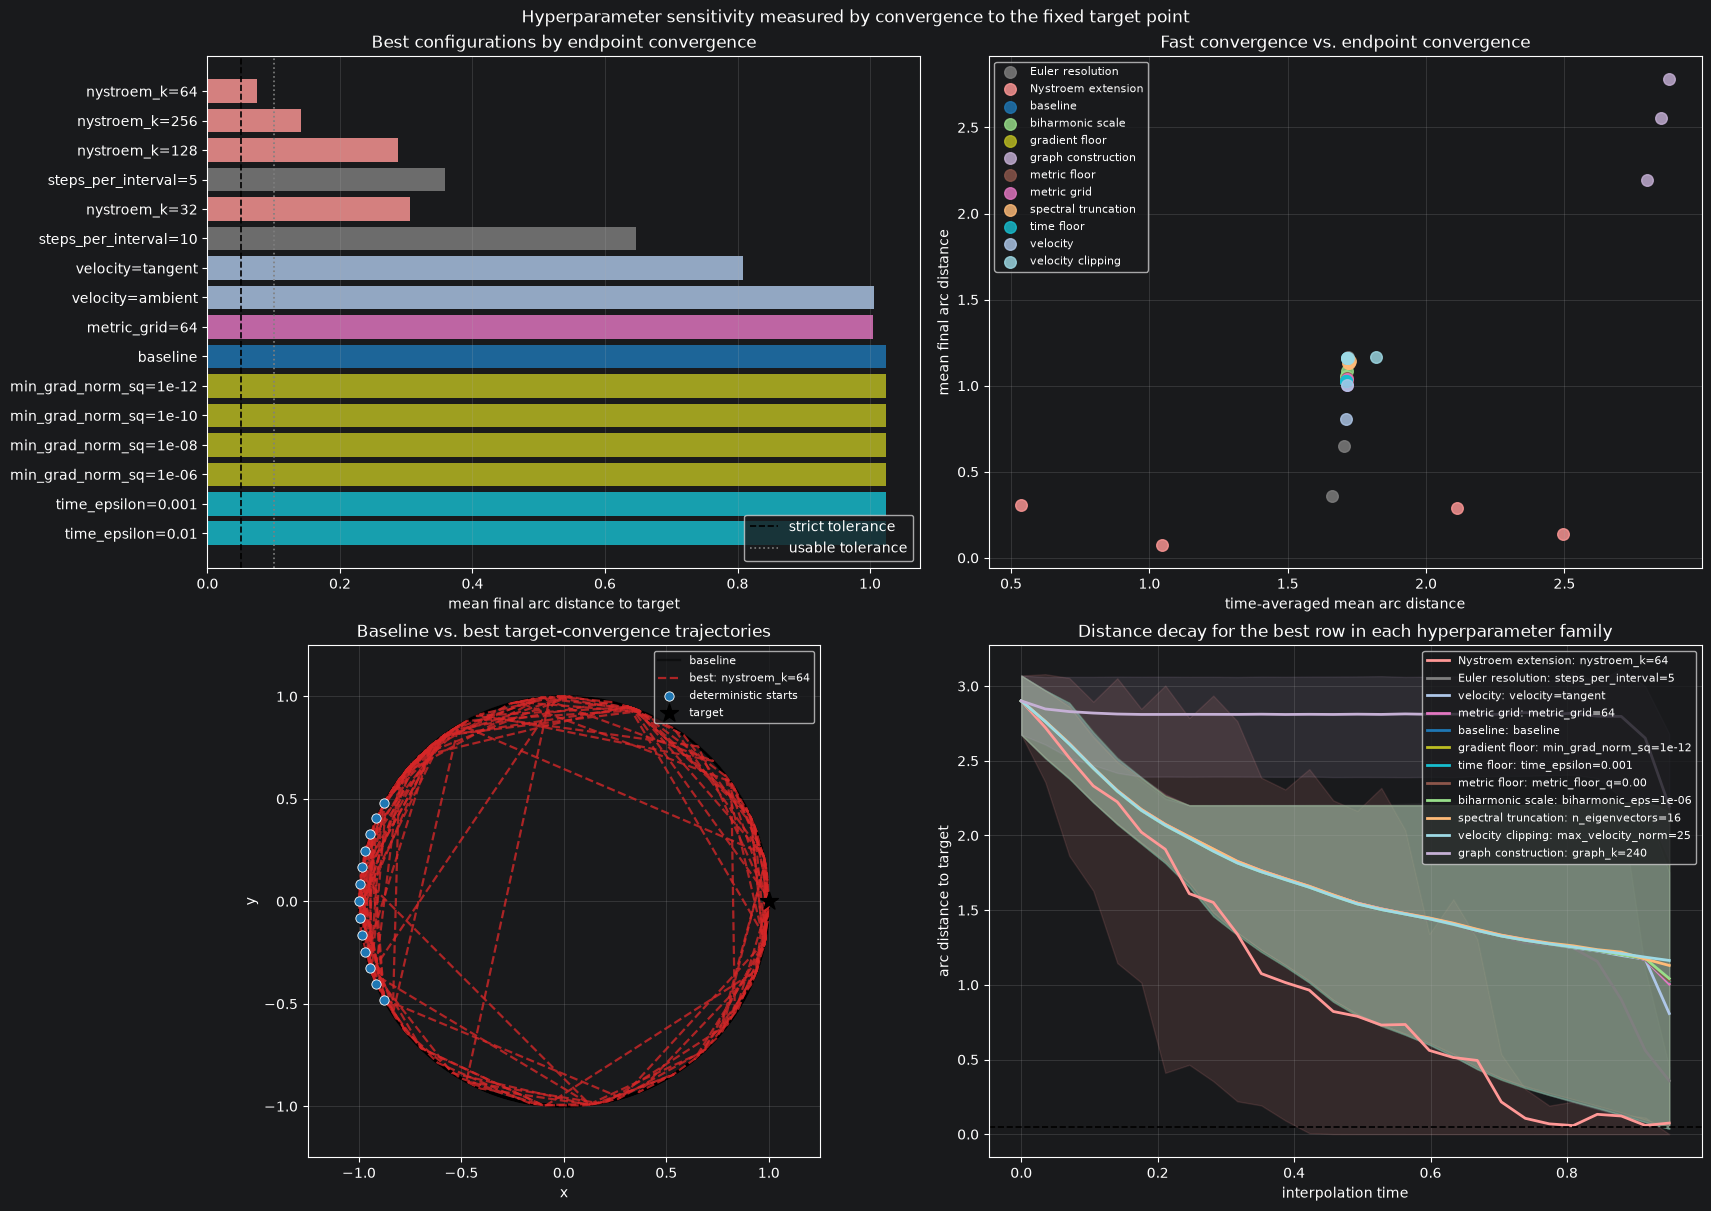

In [31]:
valid_sweep = sweep_df[sweep_df['error'].eq('')].copy()
if valid_sweep.empty:
    raise RuntimeError('No valid hyperparameter sweep rows are available to plot. Rerun the sweep cell and inspect its error column.')

axis_names = list(valid_sweep['axis'].drop_duplicates())
axis_colors = dict(zip(axis_names, plt.cm.tab20(np.linspace(0.0, 1.0, len(axis_names)))))

fig, axes = plt.subplots(2, 2, figsize=(17, 12), constrained_layout=True)
ax_rank, ax_auc, ax_paths, ax_decay = axes.ravel()

top_ranked = valid_sweep.nsmallest(16, 'rank_score').iloc[::-1]
ax_rank.barh(
    top_ranked['name'],
    top_ranked['mean_final_arc'],
    color=[axis_colors[axis] for axis in top_ranked['axis']],
    alpha=0.82,
)
ax_rank.axvline(sweep_convergence_tolerance, color='black', linewidth=1.2, linestyle='--', label='strict tolerance')
ax_rank.axvline(sweep_usable_tolerance, color='tab:gray', linewidth=1.2, linestyle=':', label='usable tolerance')
ax_rank.set_xlabel('mean final arc distance to target')
ax_rank.set_title('Best configurations by endpoint convergence')
ax_rank.legend(loc='lower right')
ax_rank.grid(axis='x', alpha=0.25)

for axis_name, group in valid_sweep.groupby('axis'):
    ax_auc.scatter(
        group['auc_mean_arc'],
        group['mean_final_arc'],
        s=70,
        alpha=0.82,
        color=axis_colors[axis_name],
        label=axis_name,
    )
ax_auc.set_xlabel('time-averaged mean arc distance')
ax_auc.set_ylabel('mean final arc distance')
ax_auc.set_title('Fast convergence vs. endpoint convergence')
ax_auc.legend(loc='best', fontsize=8)
ax_auc.grid(alpha=0.25)

baseline_name = baseline_sweep_config['name']
best_name = valid_sweep.sort_values(['rank_score', 'mean_final_arc']).iloc[0]['name']
path_names_to_plot = [baseline_name]
if best_name != baseline_name:
    path_names_to_plot.append(best_name)

path_styles = {
    baseline_name: {'color': 'black', 'linestyle': '-', 'alpha': 0.42, 'label': 'baseline'},
    best_name: {'color': 'tab:red', 'linestyle': '--', 'alpha': 0.78, 'label': f'best: {best_name}'},
}

ax_paths.scatter(
    all_generated_points[:, 0],
    all_generated_points[:, 1],
    s=4,
    alpha=0.04,
    edgecolors='none',
    color='tab:gray',
)
for path_name in path_names_to_plot:
    path = sweep_paths[path_name]
    style = path_styles[path_name]
    for curve_idx in range(sweep_deterministic_starts.shape[0]):
        ax_paths.plot(
            path[:, curve_idx, 0],
            path[:, curve_idx, 1],
            color=style['color'],
            linestyle=style['linestyle'],
            alpha=style['alpha'],
            linewidth=1.6,
            label=style['label'] if curve_idx == 0 else None,
        )
ax_paths.scatter(
    sweep_deterministic_starts[:, 0],
    sweep_deterministic_starts[:, 1],
    s=45,
    color='tab:blue',
    edgecolors='white',
    linewidths=0.6,
    label='deterministic starts',
    zorder=4,
)
ax_paths.scatter(sweep_target[0], sweep_target[1], s=180, marker='*', color='black', label='target', zorder=5)
ax_paths.add_patch(plt.Circle((0, 0), radius, fill=False, color='black', linewidth=2))
ax_paths.set_aspect('equal', adjustable='box')
ax_paths.set_xlim(-plot_limit, plot_limit)
ax_paths.set_ylim(-plot_limit, plot_limit)
ax_paths.set_xlabel('x')
ax_paths.set_ylabel('y')
ax_paths.set_title('Baseline vs. best target-convergence trajectories')
ax_paths.legend(loc='upper right', fontsize=8)
ax_paths.grid(alpha=0.25)

best_by_axis = valid_sweep.sort_values(['rank_score', 'mean_final_arc']).groupby('axis', sort=False).head(1)
for _, row in best_by_axis.iterrows():
    arcs = sweep_arcs[row['name']]
    ax_decay.plot(
        sweep_times,
        arcs.mean(axis=1),
        linewidth=2.0,
        color=axis_colors[row['axis']],
        label=f"{row['axis']}: {row['name']}",
    )
    ax_decay.fill_between(
        sweep_times,
        np.quantile(arcs, 0.10, axis=1),
        np.quantile(arcs, 0.90, axis=1),
        color=axis_colors[row['axis']],
        alpha=0.12,
    )
ax_decay.axhline(sweep_convergence_tolerance, color='black', linewidth=1.2, linestyle='--')
ax_decay.set_xlabel('interpolation time')
ax_decay.set_ylabel('arc distance to target')
ax_decay.set_title('Distance decay for the best row in each hyperparameter family')
ax_decay.legend(loc='upper right', fontsize=8)
ax_decay.grid(alpha=0.25)

fig.suptitle('Hyperparameter sensitivity measured by convergence to the fixed target point')
plt.show()

**Reading the sweep.** Use `mean_final_arc` as the primary quality metric because it directly measures convergence of the produced trajectories to the target point on `S^1`. `p90_final_arc` and `max_final_arc` flag whether a setting only works for easy starts, while `converged_frac_0p05` and `converged_frac_0p10` show strict and relaxed endpoint success rates. `auc_mean_arc` distinguishes configurations that approach the target early from ones that only arrive near the final time. `max_radius_error` should remain close to numerical precision; larger values indicate that a setting is fighting the projection step rather than producing clean manifold-respecting trajectories.

The ranked table is deliberately one-factor-at-a-time around the current notebook baseline, so it identifies sensitive hyperparameters without turning the section into a full factorial search. If several rows have nearly identical endpoint error, prefer the simpler and cheaper row: cached eigensystem, fewer Nystroem neighbors, coarser metric grid, and lower Euler resolution.

In [183]:
# Best target-convergence hyperparameter configuration extracted from the sweep output.
# Source: target-convergence-hparam-sweep ranked table.
# Selection criterion in the sweep: lowest rank_score = mean_final_arc + 0.25 * p90_final_arc.

from pprint import pprint
import pandas as pd

best_target_convergence_config = {
    'construction_source': 'uniform circle samples only',
    'graph_k': 400,
    'n_eigenvectors': 50,
    'biharmonic_eps': 1e-8,
    'nystroem_k': 64,
    'target_embedding': 'nystroem',
    'velocity_mode': 'metric_normalized',
    'metric_grid': 256,
    'metric_floor_quantile': 0.05,
    'normalize_global_scale': True,
    'min_gradient_norm_sq': 0.0,
    'time_epsilon': 1e-6,
    'max_velocity_norm': None,
    'steps_per_interval': 15,
}

best_target_convergence_metrics = {
    'selected_row': 'nystroem_k=64',
    'axis': 'Nystroem extension',
    'mean_final_arc': 0.07463114708662033,
    'median_final_arc': 0.000151,
    'p90_final_arc': 0.000329,
    'max_final_arc': 1.149860,
    'converged_frac_0p05': 0.92,
    'converged_frac_0p10': 0.92,
    'auc_mean_arc': 1.043938,
    'mean_path_length': 7.473785,
    'monotone_step_fraction': 0.745185,
    'max_radius_error': 1.192093e-07,
    'sigma': 0.12584882945296524,
    'basis_source': 'cached notebook eigensystem',
}

print('Best target-convergence configuration extracted from the sweep:')
pprint(best_target_convergence_config, sort_dicts=False)
print()
print('Quality metrics for the selected row:')
pprint(best_target_convergence_metrics, sort_dicts=False)

best_target_convergence_config_table = pd.DataFrame(
    [
        {'hyperparameter': key, 'value': repr(value)}
        for key, value in best_target_convergence_config.items()
    ]
)
best_target_convergence_metrics_table = pd.DataFrame(
    [
        {key: repr(value) for key, value in best_target_convergence_metrics.items()}
    ]
)

display(best_target_convergence_config_table)
display(best_target_convergence_metrics_table)

best_target_convergence_config

Best target-convergence configuration extracted from the sweep:
{'construction_source': 'uniform circle samples only',
 'graph_k': 400,
 'n_eigenvectors': 50,
 'biharmonic_eps': 1e-08,
 'nystroem_k': 64,
 'target_embedding': 'nystroem',
 'velocity_mode': 'metric_normalized',
 'metric_grid': 256,
 'metric_floor_quantile': 0.05,
 'normalize_global_scale': True,
 'min_gradient_norm_sq': 0.0,
 'time_epsilon': 1e-06,
 'max_velocity_norm': None,
 'steps_per_interval': 15}

Quality metrics for the selected row:
{'selected_row': 'nystroem_k=64',
 'axis': 'Nystroem extension',
 'mean_final_arc': 0.07463114708662033,
 'median_final_arc': 0.000151,
 'p90_final_arc': 0.000329,
 'max_final_arc': 1.14986,
 'converged_frac_0p05': 0.92,
 'converged_frac_0p10': 0.92,
 'auc_mean_arc': 1.043938,
 'mean_path_length': 7.473785,
 'monotone_step_fraction': 0.745185,
 'max_radius_error': 1.192093e-07,
 'sigma': 0.12584882945296524,
 'basis_source': 'cached notebook eigensystem'}


,hyperparameter,value
0,construction_source,'uniform circle samples only'
1,graph_k,400
2,n_eigenvectors,50
3,biharmonic_eps,1e-08
4,nystroem_k,64
5,target_embedding,'nystroem'
6,velocity_mode,'metric_normalized'
7,metric_grid,256
8,metric_floor_quantile,0.05
9,normalize_global_scale,True


,selected_row,axis,mean_final_arc,median_final_arc,p90_final_arc,max_final_arc,converged_frac_0p05,converged_frac_0p10,auc_mean_arc,mean_path_length,monotone_step_fraction,max_radius_error,sigma,basis_source
0,'nystroem_k=64','Nystroem extension',0.07463114708662033,0.000151,0.000329,1.14986,0.92,0.92,1.043938,7.473785,0.745185,1.192093e-07,0.12584882945296524,'cached notebook eigensystem'


{'construction_source': 'uniform circle samples only',
 'graph_k': 400,
 'n_eigenvectors': 50,
 'biharmonic_eps': 1e-08,
 'nystroem_k': 64,
 'target_embedding': 'nystroem',
 'velocity_mode': 'metric_normalized',
 'metric_grid': 256,
 'metric_floor_quantile': 0.05,
 'normalize_global_scale': True,
 'min_gradient_norm_sq': 0.0,
 'time_epsilon': 1e-06,
 'max_velocity_norm': None,
 'steps_per_interval': 15}

## Toy Riemannian Flow Matching on the unit circle

In this toy example, the left angular Gaussian is the control distribution and the right angular Gaussian is the perturbed distribution. The CellFlow model is trained with the `otrfm` solver, using the spectral Nystroem pre-metric fit above to define Riemannian interpolation on the unit-circle manifold. The same projection hook is passed into the solver so training-time interpolation remains on `S^1`.

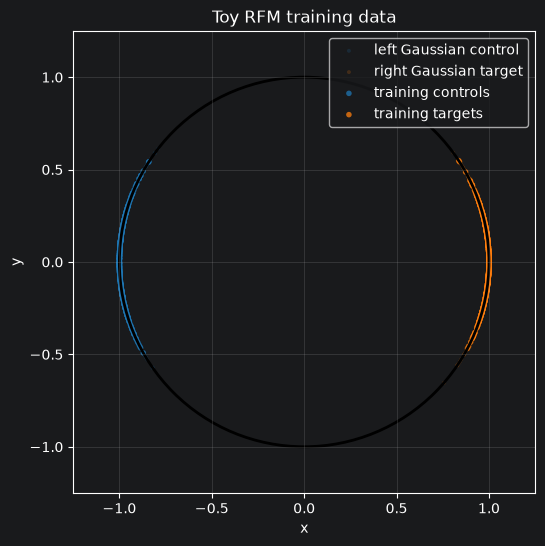

In [11]:
import anndata as ad
import functools
import jax
import optax
import pandas as pd
import flax.linen as nn

from cellflow.model import CellFlow
from cellflow.utils import match_linear

toy_rng = np.random.default_rng(2026)
toy_n_train_per_group = 512

toy_left_idx = toy_rng.choice(left_gaussian_points.shape[0], toy_n_train_per_group, replace=False)
toy_right_idx = toy_rng.choice(right_gaussian_points.shape[0], toy_n_train_per_group, replace=False)

toy_train_points = np.vstack(
    (
        left_gaussian_points[toy_left_idx],
        right_gaussian_points[toy_right_idx],
    )
).astype(np.float32)

toy_obs = pd.DataFrame(
    {
        "is_control": np.concatenate(
            (
                np.ones(toy_n_train_per_group, dtype=bool),
                np.zeros(toy_n_train_per_group, dtype=bool),
            )
        ),
        "toy_perturbation": pd.Categorical(
            ["control"] * toy_n_train_per_group + ["right_shift"] * toy_n_train_per_group
        ),
    },
    index=[f"toy_cell_{i}" for i in range(2 * toy_n_train_per_group)],
)

toy_adata = ad.AnnData(X=toy_train_points, obs=toy_obs)
toy_adata.uns["toy_perturbation_embeddings"] = {
    "control": np.array([0.0], dtype=np.float32),
    "right_shift": np.array([1.0], dtype=np.float32),
}

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    left_gaussian_points[:, 0],
    left_gaussian_points[:, 1],
    s=8,
    alpha=0.18,
    edgecolors="none",
    color="tab:blue",
    label="left Gaussian control",
)
ax.scatter(
    right_gaussian_points[:, 0],
    right_gaussian_points[:, 1],
    s=8,
    alpha=0.18,
    edgecolors="none",
    color="tab:orange",
    label="right Gaussian target",
)
ax.scatter(
    toy_train_points[:toy_n_train_per_group, 0],
    toy_train_points[:toy_n_train_per_group, 1],
    s=16,
    alpha=0.75,
    edgecolors="none",
    color="tab:blue",
    label="training controls",
)
ax.scatter(
    toy_train_points[toy_n_train_per_group:, 0],
    toy_train_points[toy_n_train_per_group:, 1],
    s=16,
    alpha=0.75,
    edgecolors="none",
    color="tab:orange",
    label="training targets",
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Toy RFM training data")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

In [12]:
toy_cf = CellFlow(toy_adata, solver="otrfm")
toy_cf.prepare_data(
    sample_rep="X",
    control_key="is_control",
    perturbation_covariates={"toy_perturbation": ("toy_perturbation",)},
    perturbation_covariate_reps={"toy_perturbation": "toy_perturbation_embeddings"},
    max_combination_length=1,
    null_value=0.0,
)

toy_train_data = toy_cf.train_data
print("cell data shape:", toy_train_data.cell_data.shape)
print("condition keys:", list(toy_train_data.condition_data))
print("control-to-perturbation mapping:", toy_train_data.control_to_perturbation)
print("perturbation labels:", toy_train_data.perturbation_idx_to_covariates)


[########################################] | 100% Completed | 102.87 ms
[########################################] | 100% Completed | 102.17 ms
[########################################] | 100% Completed | 102.27 ms
cell data shape: (1024, 2)
condition keys: ['toy_perturbation']
control-to-perturbation mapping: {0: array([0], dtype=int32)}
perturbation labels: {0: ['right_shift']}


### Train a compact OTRFM model

This is intentionally much smaller than the PBMC model: the state is only 2D, there is one toy condition, and the goal is to visualize the learned field rather than maximize predictive accuracy.


In [13]:
toy_layers_before_pool = {
    "toy_perturbation": {"layer_type": "mlp", "dims": [16], "dropout_rate": 0.0},
}
toy_layers_after_pool = {
    "layer_type": "mlp",
    "dims": [16],
    "dropout_rate": 0.0,
}

toy_match_fn = functools.partial(match_linear, epsilon=0.5, tau_a=1.0, tau_b=1.0)

toy_cf.prepare_model(
    condition_mode="deterministic",
    regularization=0.0,
    pooling="mean",
    pooling_kwargs={},
    layers_before_pool=toy_layers_before_pool,
    layers_after_pool=toy_layers_after_pool,
    condition_embedding_dim=16,
    cond_output_dropout=0.0,
    condition_encoder_kwargs={},
    pool_sample_covariates=True,
    time_freqs=16,
    time_encoder_dims=[32, 32],
    time_encoder_dropout=0.0,
    hidden_dims=[32, 32],
    hidden_dropout=0.0,
    conditioning="concatenation",
    decoder_dims=[32, 32],
    vf_act_fn=nn.silu,
    vf_kwargs=None,
    probability_path={"constant_noise": 0.0},
    match_fn=toy_match_fn,
    optimizer=optax.adam(1e-3),
    solver_kwargs={"projection_fn": project_to_unit_sphere},
    layer_norm_before_concatenation=False,
    linear_projection_before_concatenation=False,
    nystroem=nystroem,
    seed=0,
)

toy_num_iterations = 300
toy_batch_size = 32
toy_cf.train(
    num_iterations=toy_num_iterations,
    batch_size=toy_batch_size,
    callbacks=[],
    valid_freq=10_000,
)


100%|██████████| 300/300 [00:54<00:00,  5.46it/s]


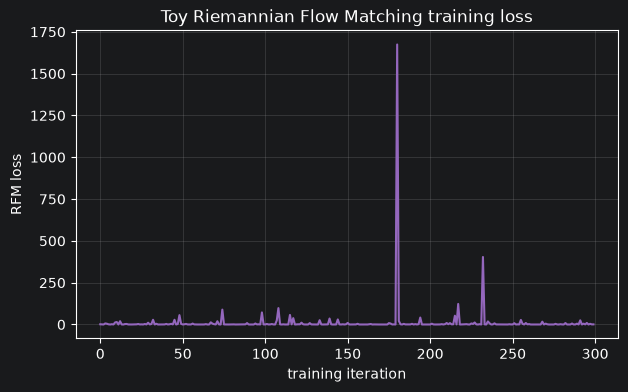

In [14]:
toy_loss = np.asarray(toy_cf.trainer.training_logs["loss"])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(toy_loss, color="tab:purple")
ax.set_xlabel("training iteration")
ax.set_ylabel("RFM loss")
ax.set_title("Toy Riemannian Flow Matching training loss")
ax.grid(alpha=0.25)
plt.show()


### Plot learned flow curves and vector field

We evaluate the trained vector field under the `right_shift` condition, integrate trajectories with an explicit Euler solver, project each Euler step back to `S^1`, and plot a quiver field at the midpoint time `t=0.5`.


In [15]:
def get_toy_condition(cf, label="right_shift"):
    condition_idx = next(
        idx
        for idx, covariates in cf.train_data.perturbation_idx_to_covariates.items()
        if covariates[0] == label
    )
    return {
        key: jnp.asarray(value[[condition_idx]])
        for key, value in cf.train_data.condition_data.items()
    }

def evaluate_learned_vector_field(cf, x, condition, t=0.5, chunk_size=512):
    x = np.asarray(x, dtype=np.float32)
    vectors = []
    encoder_noise = jnp.zeros((1, cf.solver.vf.condition_embedding_dim))

    for start in range(0, x.shape[0], chunk_size):
        stop = min(start + chunk_size, x.shape[0])
        x_chunk = jnp.asarray(x[start:stop])
        t_chunk = jnp.full((x_chunk.shape[0], 1), t)
        v_chunk = cf.solver.vf_state_inference.apply_fn(
            {"params": cf.solver.vf_state_inference.params},
            t_chunk,
            x_chunk,
            condition,
            encoder_noise,
            train=False,
        )[0]
        vectors.append(np.asarray(v_chunk))

    return np.vstack(vectors)

def integrate_learned_flow(cf, x0, condition, n_steps=80, projection_fn=None):
    x = np.asarray(x0, dtype=np.float32)
    trajectory = np.empty((n_steps + 1, x.shape[0], x.shape[1]), dtype=np.float32)
    trajectory[0] = x
    dt = 1.0 / n_steps

    for step in range(n_steps):
        t = step * dt
        v = evaluate_learned_vector_field(cf, x, condition, t=t)
        x = x + dt * v
        if projection_fn is not None:
            x = np.asarray(projection_fn(jnp.asarray(x)), dtype=np.float32)
        trajectory[step + 1] = x

    return trajectory


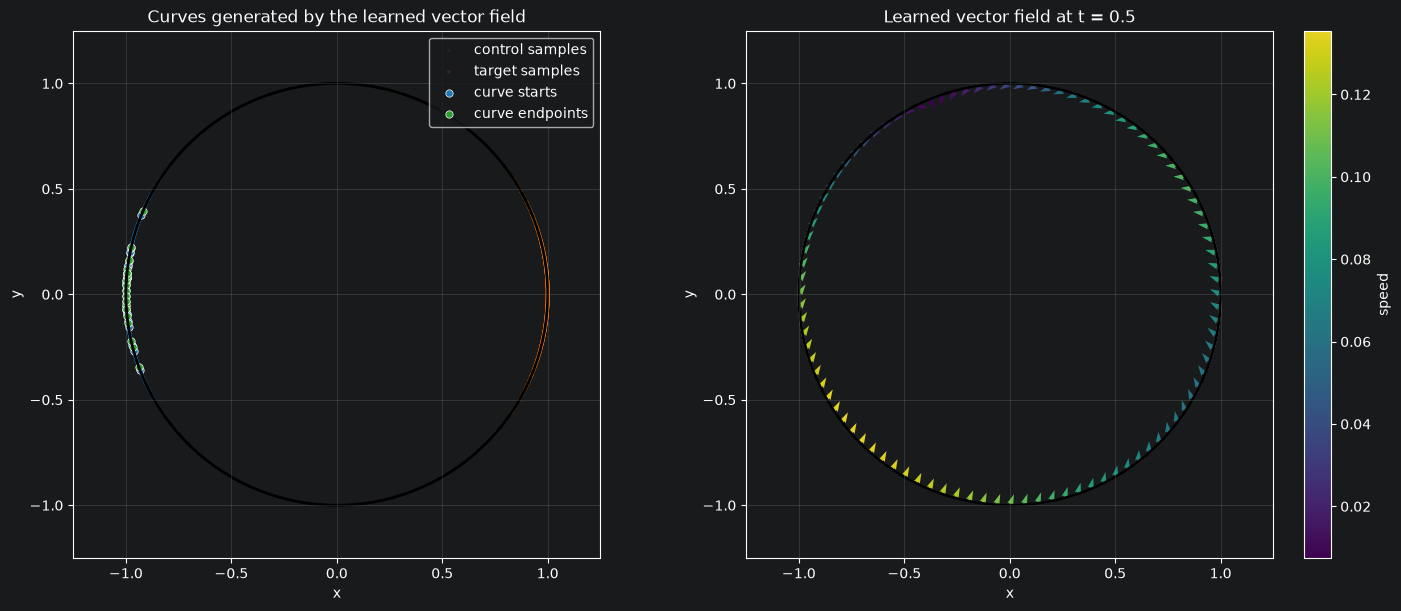

In [16]:
toy_condition = get_toy_condition(toy_cf, label="right_shift")

n_flow_curves = 24
curve_start_idx = toy_rng.choice(left_gaussian_points.shape[0], n_flow_curves, replace=False)
curve_start_points = left_gaussian_points[curve_start_idx].astype(np.float32)
toy_flow_curves = integrate_learned_flow(
    toy_cf,
    curve_start_points,
    toy_condition,
    n_steps=80,
    projection_fn=project_to_unit_sphere,
)

vector_theta = np.linspace(0.0, 2.0 * np.pi, 96, endpoint=False)
circle_grid_points = (radius * np.column_stack((np.cos(vector_theta), np.sin(vector_theta)))).astype(np.float32)

vector_grid = evaluate_learned_vector_field(toy_cf, circle_grid_points, toy_condition, t=0.5)
vector_speed = np.linalg.norm(vector_grid, axis=1)
vector_grid_unit = vector_grid / np.maximum(vector_speed[:, None], 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

ax = axes[0]
ax.scatter(
    left_gaussian_points[:, 0],
    left_gaussian_points[:, 1],
    s=8,
    alpha=0.12,
    edgecolors="none",
    color="tab:blue",
    label="control samples",
)
ax.scatter(
    right_gaussian_points[:, 0],
    right_gaussian_points[:, 1],
    s=8,
    alpha=0.12,
    edgecolors="none",
    color="tab:orange",
    label="target samples",
)
for curve_idx in range(n_flow_curves):
    ax.plot(
        toy_flow_curves[:, curve_idx, 0],
        toy_flow_curves[:, curve_idx, 1],
        color="black",
        alpha=0.7,
        linewidth=1.2,
    )
ax.scatter(
    toy_flow_curves[0, :, 0],
    toy_flow_curves[0, :, 1],
    s=28,
    color="tab:blue",
    edgecolors="white",
    linewidths=0.5,
    label="curve starts",
)
ax.scatter(
    toy_flow_curves[-1, :, 0],
    toy_flow_curves[-1, :, 1],
    s=28,
    color="tab:green",
    edgecolors="white",
    linewidths=0.5,
    label="curve endpoints",
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Curves generated by the learned vector field")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)

ax = axes[1]
ax.scatter(
    all_generated_points[:, 0],
    all_generated_points[:, 1],
    s=4,
    alpha=0.08,
    edgecolors="none",
    color="tab:gray",
)
quiver = ax.quiver(
    circle_grid_points[:, 0],
    circle_grid_points[:, 1],
    vector_grid_unit[:, 0],
    vector_grid_unit[:, 1],
    vector_speed,
    cmap="viridis",
    angles="xy",
    scale_units="xy",
    scale=18,
    width=0.004,
    alpha=0.9,
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Learned vector field at t = 0.5")
ax.grid(alpha=0.25)
fig.colorbar(quiver, ax=ax, label="speed")

plt.show()